In [1]:
import scipy.io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from scipy import stats
import glob
from tqdm import tqdm
from itertools import combinations
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.colors as mcolors
import seaborn as sb
import sys
from itertools import combinations
from collections import defaultdict
import os
from pathlib import Path

In [2]:
base_directory = '/Users/elnagar/ownCloud/Salmas_PhD_NM/Project3(CVlearn)/Code/Results/'
figures_path = '/Users/elnagar/ownCloud/Salmas_PhD_NM/Project3(CVlearn)/Code/figures/'


participants = range(1, 126)
temp_excluded_participants = [107, 109]
participants = [p for p in participants if p not in temp_excluded_participants]
# 61,69,70,77,83,87
# participants = [93]
excluded_ppts = {'low_accuracy_test': [],
                 'high_missed_trials': []}

# add if any participants shall be excluded
ZT_configs = [3, 4, 5, 6, 10, 11, 12, 17, 18,
              24, 13, 19, 20, 25, 26, 27, 31, 32, 33, 34]
SHI_configs = [1, 2, 7, 8, 9, 14, 15, 16, 21, 22, 23, 28, 29, 30, 35, 36]
phases = ['training', 'test']
inference = ['old', 'new']

# Differentiate participants by the 4 conditions: interleaved, blocked1, blocked2, blocked3 // aka interleaved, mixed interleaved, configuration blocked, category blocked
# The 4 conditions are: interleaved switch frequency, mixed interleaved,
# low switch frequency = blocking one configuration for 10 trials
# categories blocked = blocking one rule (cat) for a whole block (30 trials)
conditions = {
    # odd numbers in the first 60 ppts
    'interleaved': lambda num: num <= 60 and num % 2 != 0,
    # even numbers in the first 60 ppts
    'mixed interleaved': lambda num: num <= 60 and num % 2 == 0,
    'category blocked': lambda num: num > 90,
    'configuration blocked': lambda num: 60 < num <= 90,
}
configurations = list(range(1, 37))

df_configurations = pd.DataFrame()
df_results = pd.DataFrame()

save_figs = True
font = {'family': 'Roboto'}
matplotlib.rc('font', **font)

In [3]:
# %% Define functions


def add_significance(ax, x1, x2, y_base, p_value, level=0, height_step=0.1, height_offset=0.00005, bars=None):
    """
    Adds significance stars on the plot.

    Parameters:
    ax -- The axis on which to plot
    x1, x2 -- The positions of the bars to compare
    y_base -- The base height (e.g., top of tallest bar in group)
    p_value -- The p-value from the statistical test
    level -- Which level above y_base to place the bar (0 = first, 1 = stacked above, etc.)
    height_step -- Space between levels of significance bars
    height_offset -- Vertical offset for text above the line
    """
    # If bars are provided and x1/x2 are indices, convert them to actual x positions (bar centers)
    if bars is not None:
        if isinstance(x1, (int, np.integer)) and isinstance(x2, (int, np.integer)):
            x1 = bars[x1].get_x() + bars[x1].get_width() / 2
            x2 = bars[x2].get_x() + bars[x2].get_width() / 2

    # Compute the height for this comparison
    height = y_base + (level + 1) * height_step

    # Clip height to stay within plot limits
    y_top = ax.get_ylim()[1]
    height = min(height, y_top - 0.01)

    if p_value < 0.05:
        # Determine significance marker
        if p_value < 0.001:
            significance = "***"
        elif p_value < 0.01:
            significance = "**"
        else:
            significance = "*"

        mid_x = (x1 + x2) / 2

        # Draw horizontal line
        ax.plot([x1, x2], [height, height],
                color='black',
                lw=1.3,
                solid_capstyle="round")

        # Add text annotation
        ax.text(mid_x,
                height + height_offset,
                significance,
                ha='center',
                va='baseline',
                color='black')

In [4]:
# %% Main Loop
for ppt_n in tqdm(participants):
    # Load results .mat file
    # file_pathway_test = f'/Users/elnagaradmin/ownCloud (2)/Salmas_PhD_NM/Project3(CVlearn)/Code/Results/sbj{participant_number}/sbj{participant_number}Test.mat'
    # Search for files starting with sbj##Test or Train because new participants (61+) have a different naming for their results files
    file_pathway_test = glob.glob(
        f'{base_directory}sbj{ppt_n}/sbj{ppt_n}Test*.mat')[0]
    file_pathway_training = glob.glob(
        f'{base_directory}sbj{ppt_n}/sbj{ppt_n}Training*.mat')[0]
    # file_pathway_training = f'/Users/elnagaradmin/ownCloud (2)/Salmas_PhD_NM/Project3(CVlearn)/Code/Results/sbj{participant_number}/sbj{participant_number}Training.mat'
    mat_test = scipy.io.loadmat(file_pathway_test)
    mat_training = scipy.io.loadmat(file_pathway_training)

    results_test = mat_test['Results']
    results_training = mat_training['Results']
    df_test = pd.DataFrame(results_test[0][0][0][0])
    df_training = pd.DataFrame(results_training[0][0][0][0])

    # (1) Preprocessing
    for column_training, column_test in zip(df_training.columns, df_test.columns):
        # convert each column to string then cut the two brackets[[]]
        df_training[f"{column_training}"] = df_training[f'{column_training}'].apply(
            lambda x: str(x)).str[2:-2]
        df_test[f"{column_test}"] = df_test[f'{column_test}'].apply(
            lambda x: str(x)).str[2:-2]
        # convert to float
        df_training[f"{column_training}"] = df_training[f"{column_training}"].apply(
            lambda x: float(x))
        df_test[f"{column_test}"] = df_test[f"{column_test}"].apply(
            lambda x: float(x))
        # Disregard trials when RT is lower than 0.3 (faster) and that are missed
        df_training = df_training[(df_training['RT'] >= 0.3) & (
            df_training['TrialLost'] == 0)]
        df_test = df_test[(df_test['RT'] >= 0.3) &
                          (df_test['TrialLost'] == 0)]
    # Exclusion criteria: scoring below 0.5 in test only (
    # <0.5 in training doesn't matter bec if they do >0.5 in test, it means they learnt).
    # excluded_ppts = {'low_accuracy_test':[],'high_missed_trials':[]}
    if df_test["Feedback"].mean() < 0.5:
        excluded_ppts['low_accuracy_test'].append(ppt_n)
    # Exclude ppts who miss 0.2 or more of trials in either trainig or test
    if len(df_training['trialN']) < 0.8*180 or len(df_test['trialN']) < 0.8*252:
        excluded_ppts['high_missed_trials'].append(ppt_n)

        # (1.2) Add which cat/ rule
    for df, configs in [(df_training, df_training['Configuration']), (df_test, df_test['Configuration'])]:
        df['cat'] = [
            'SHI' if config in SHI_configs else 'ZT' if config in ZT_configs else None for config in configs]
    # (1.3) Sanity check: Get number of trials after dropping trial lost
    df_results.at[ppt_n, 'trialN_training'] = len(df_training['trialN'])
    df_results.at[ppt_n, 'trialN_test'] = len(df_test['trialN'])

    # Visualise conditions
    # TODO: fix figure
    # interleaved, mixed interleaved, low
    # if ppt_n in [100]:
    #     # Limit data to first 30 rows
    #     df_training_30 = df_training.head(30)
    #     df_test_30 = df_test.head(30)
    #     line_w = 1  # Bar width

    #     # List for training and test data
    #     data_sets = [('Training', df_training_30), ('Test', df_test_30)]

    #     # Loop through both training and test datasets
    #     for label, data_frame in data_sets:
    #         # Ensure trialN and Configuration are integers
    #         data_frame['trialN'] = data_frame['trialN'].astype(int)
    #         data_frame['Configuration'] = data_frame['Configuration'].astype(
    #             int)

    #         # Generate a color map for the unique configurations
    #         unique_configs = data_frame['Configuration'].unique()
    #         cmap = plt.cm.get_cmap('tab20', len(unique_configs))  # Colormap
    #         color_map = {config: cmap(i)
    #                      for i, config in enumerate(unique_configs)}

    #         # Create a figure for each dataset (training or test)
    #         plt.figure(figsize=(10, 4))

    #         # Get the y-axis limits to set the height of the bars
    #         ylim = plt.ylim()

    #         # Plot bars for the configurations
    #         for i, config in enumerate(data_frame['Configuration']):
    #             trialN_value = data_frame['trialN'].iloc[i]
    #             config_value = int(config)

    #             # Plot bars with black borders and fixed width for uniformity
    #             plt.bar(trialN_value, ylim[1], width=line_w, color=color_map.get(
    #                 config_value, 'gray'), edgecolor='black')

    #         # Set bottom x-axis labels (Trial Number) and adjust text size
    #         plt.xticks(data_frame['trialN'], data_frame['trialN'], fontsize=14)
    #         plt.xlabel("Trial Number", fontsize=14)

    #         # Create top x-axis labels (Configuration Number)
    #         ax = plt.gca()  # Get current axes
    #         ax2 = ax.twiny()  # Create a second x-axis at the top
    #         ax2.set_xlim(ax.get_xlim())  # Ensure the limits match
    #         # Place the same ticks as on the bottom x-axis
    #         ax2.set_xticks(data_frame['trialN'])
    #         ax2.set_xticklabels(data_frame['Configuration'].astype(
    #             int), fontsize=14)  # Set font size for top x-axis
    #         # Label for the top x-axis
    #         ax2.set_xlabel("Configurations", fontsize=14)
    #         # Remove the y-axis text
    #         plt.yticks([])
    #         # plt.title(f"{label} Configurations for Participant {ppt_n}")

    #         # Save figure if required
    #         if save_figs:
    #             plt.savefig(
    #                 f'{figures_path}/conditions_visualisation_{label}_{ppt_n}.png', dpi=1000, transparent=True)

    #         # Show the plot
    #         plt.show()

    # (3) Create results df with desired scores for every participant
    df_results.at[ppt_n, 'ppt_number'] = ppt_n

    # three scores for both days (6 columns)
    results = ['Feedback', 'Action', 'RT', ]
    for result in results:
        df_results.at[ppt_n, f'{result}_training'] = df_training[result].mean()
        df_results.at[ppt_n, f'{result}_test'] = df_test[result].mean()
    # Old/new accuracy the mean of the outcome for the configurations in test
    # that are (old) and are not (new) in configuration in training
    train_configurations = set(df_training['Configuration'])
    # Calculate the mean of the outcome for test rows where the configuration is present in the training set (old)
    df_results.at[ppt_n, 'old_accuracy_test'] = df_test[df_test['Configuration'].isin(
        train_configurations)]['Feedback'].mean()
    # Calculate the mean of the outcome for test rows where the configuration is not present in the training set (new)
    df_results.at[ppt_n, 'new_accuracy_test'] = df_test[~df_test['Configuration'].isin(
        train_configurations)]['Feedback'].mean()
    # Old and new configurations accuracy difference
    df_results.at[ppt_n, 'oldnew_acccuracy_difference'] = df_results.at[ppt_n,
                                                                        'old_accuracy_test'] - df_results.at[ppt_n, 'new_accuracy_test']

    df_results.at[ppt_n, 'SHI'] = df_test.query(
        'cat == "SHI"')['Feedback'].mean()
    df_results.at[ppt_n, 'ZT'] = df_test.query(
        'cat == "ZT"')['Feedback'].mean()


# %%# (4) Get RT and accuracy per feature value
    # 4.1. Create grid: define the range of values for x and y
    y_values = range(1, 7)
    x_values = range(1, 7)

    # Initialize an empty list to store the grid information
    grid_data = []

    # Generate the grid and combination numbers
    combination_number = 0
    for y in y_values:
        for x in x_values:
            combination_number += 1
            grid_data.append((y, x, combination_number))

    # Create a DataFrame from the grid data
    df_feature_value = pd.DataFrame(
        grid_data, columns=['y', 'x', 'combination_number'])

    # Get the diagonal index
    df_feature_value['feature_value'] = (
        df_feature_value['x'] - df_feature_value['y']).abs()

    # Merge two dfs so that we map the configurations in our current dfs to the right feature values
    df_feature_value_selected = df_feature_value[[
        'combination_number', 'feature_value']]

    df_test = pd.merge(df_test, df_feature_value_selected,
                       left_on='Configuration', right_on='combination_number', how='left')
    df_test = df_test.drop(columns=['combination_number'])

    df_training = pd.merge(df_training, df_feature_value_selected,
                           left_on='Configuration', right_on='combination_number', how='left')
    df_training = df_training.drop(columns=['combination_number'])

    # 4.2. Get the outcome and RT of the different feature values and put it in results
    features = list(set(df_test['feature_value']))
    for feature in features:
        # Get mean accuracy per feature in the test phase only
        df_results.at[ppt_n, f'Accuracy_FV{feature}'] = df_test.query(
            f'feature_value == {feature}')['Feedback'].mean()
        # Get mean RT per feature
        df_results.at[ppt_n, f'RT_FV{feature}'] = df_test.query(
            f'feature_value == {feature}')['RT'].mean()

    # (5) In the training phase (blocked design only) get the accuracy when
    # new triplets are presented. Skip the first ever triplet to be presented.
    # get accuracy only for when a triplet is the first time.

    # Define the segment size
    segment_size = 30

    # Initialize list to store segment means
    segment_means = []

    # Loop over segments, skipping the first 3 trials in the first segment
    # If the design is blocked only (i.e. the sum of unique configurations it has is not = 36, then get accuracy of triplets)
    if len(set(df_training['Configuration'])) < 36:
        for s, start_idx in enumerate(range(segment_size, len(df_training), segment_size)):
            # Get the first 3 rows of the current segment
            segment_rows = df_training.iloc[start_idx:start_idx + 3]

            # Calculate the mean of the 'feeback' column for these rows
            df_results.at[ppt_n,
                          f'Accuracy_Triplet{s+1}'] = segment_rows['Feedback'].mean()

    # Configurations df
    for configuration in configurations:
        df_configurations.loc[ppt_n, 'ppt_number'] = ppt_n
        # Get mean accuracy for every configuration
        df_configurations.loc[ppt_n,
                              f'config_{configuration}'] = df.query(
                                  f'Configuration == {configuration}')['Feedback'].mean()
    # %% (6) Recency Effect. Analysis of test based on last 6 configs presented in training
        # Last 6 trials for interleaved.
        # Blocked : last 6 configuration (shown in the last 60 trials).
        # Blocked 1: 6 configurations in last 60.
        # Blocked 2: more similar to interleaved,
        # set of 6 configurations in the last bit (6 trials or more)
    recent_configurations = []
    # add this for categories blocked:
    if conditions['interleaved'](ppt_n) or conditions['category blocked'](ppt_n):
        row = 3
        sorted_df = df_training.sort_values('trialN')
        last_n_rows = sorted_df.tail(row)
        configurations_set = set(last_n_rows['Configuration'])
        while len(configurations_set) != 3:
            # Get the last 6 rows from the sorted DataFrame
            last_n_rows = sorted_df.tail(row)
            # Extract the 'Configuration' values and convert to a set
            configurations_set = set(last_n_rows['Configuration'])
            if len(configurations_set) < 3:
                row += 1
            elif len(configurations_set) > 3:
                row -= 1
        # print(ppt_n, 'int or bl',
        #       f'len={len(configurations_set)}', f'row = {row}')
        recent_configurations.append(configurations_set)

    elif conditions['mixed interleaved'](ppt_n) or conditions['configuration blocked'](ppt_n):
        row = 30
        sorted_df = df_training.sort_values('trialN')
        last_n_rows = sorted_df.tail(row)
        configurations_set = set(last_n_rows['Configuration'])
        while len(configurations_set) != 3:
            # Get the last 6 rows from the sorted DataFrame
            last_n_rows = sorted_df.tail(row)
            # Extract the 'Configuration' values and convert to a set
            configurations_set = set(last_n_rows['Configuration'])
            if len(configurations_set) < 3:
                row += 1
            elif len(configurations_set) > 3:
                row -= 1
        # print(ppt_n, 'bl or bl2',
        #       f'len={len(configurations_set)}', f'row = {row}')
        recent_configurations.append(configurations_set)

    # then for the same ppt's test, get the mean df['Feedback'] filtered by the config obtained
    filtered_recent_configs = df_test.query(
        f'Configuration in {list(configurations_set)}')['Feedback']
    filtered_nonrecent_configs = df_test.query(
        f'Configuration not in {list(configurations_set)}')['Feedback']
    df_results.at[ppt_n, 'Recent_3_configs'] = filtered_recent_configs.mean()
    df_results.at[ppt_n,
                  'Nonrecent_configs'] = filtered_nonrecent_configs.mean()
    # sanity check:

    if (len(filtered_recent_configs) + len(filtered_nonrecent_configs)) != len(df_test['trialN']):
        print('Warning, recent and non-recent configs are not same!')


100%|██████████| 123/123 [00:11<00:00, 11.04it/s]


In [6]:
excluded_ppts

{'low_accuracy_test': [67, 86, 89], 'high_missed_trials': [66, 70, 115, 118]}

In [5]:
# %% EXCLUDE PPTS
# Flatten excluded ppt dictionary values into a list of excluded participant numbers
excluded_ppts_list = [num for sublist in excluded_ppts.values()
                      for num in sublist]

# Filter out rows where 'ppt_number' is in the excluded list
df_results = df_results[~df_results['ppt_number'].isin(excluded_ppts_list)]
df_configurations = df_configurations[~df_configurations['ppt_number'].isin(
    excluded_ppts_list)]

# %% Create mean scores for old/new, and training/test by condition

# each 1 of the 4 conditions will have a list of test scores and a list of training scores, for all participants
# goal is to look like this:
# cond_accuracy = {'mixed interleaved': {'training': [list of scores for all ppts],
# 'test': [list of scores for all ppts]}}
cond_accuracy = {cond: {phase: [] for phase in phases}
                 for cond in conditions}

# each 1 of the 4 conditions will have an old score and a new score, for all participants
# goal is same thing as cond_accuracy but with old/new instead of training/test
oldnew_accuracy = {cond: {inf: [] for inf in inference}
                   for cond in conditions}

for num in df_results['ppt_number']:
    # filter once for efficiency
    filtered_row = df_results[df_results['ppt_number'] == num]
    for cond, ppt_range in conditions.items():
        if ppt_range(num):
            for phase, inf in zip(phases, inference):
                feedback_key = f'Feedback_{phase}'
                cond_accuracy[cond][phase].append(
                    filtered_row[feedback_key].item())
                oldnew_accuracy[cond][inf].append(
                    filtered_row[f'{inf}_accuracy_test'].item())
# sanity check
# for cond in conditions.keys():
#     for phase, inf in zip(phases, inference):
#         # print(cond,phase)
#         print(
#             f'Mean {phase} score for {cond} (n={len(cond_accuracy[cond][phase])}) = {np.mean(cond_accuracy[cond][phase])}')
#         print(
#             f'Mean {inf} score for {cond} (n={len(oldnew_accuracy[cond][inf])}) = {np.mean(oldnew_accuracy[cond][inf])}')

In [6]:
# Summary statistics for feedback measures in df_results
for column in ["Feedback_training", "Feedback_test"]:
    print(f"\n=== {column} ===")
    if column in df_results.columns:
        stats = df_results[column].agg(["mean", "std", "min", "max"])
        print(stats.to_string())
    else:
        print(f"Column '{column}' not found in df_results")



=== Feedback_training ===
mean    0.885982
std     0.103140
min     0.494318
max     0.983333

=== Feedback_test ===
mean    0.762317
std     0.128886
min     0.514170
max     0.980159


## Visualisations/ Figures

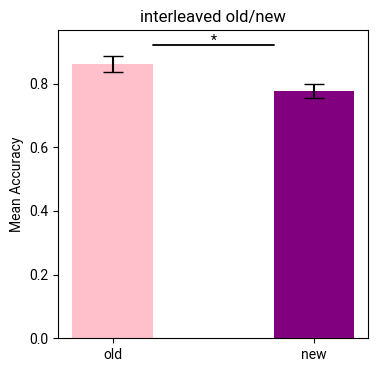

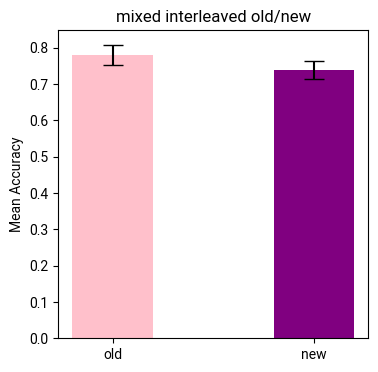

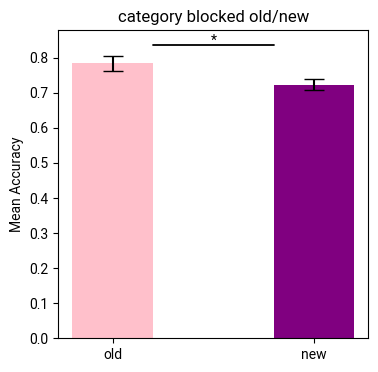

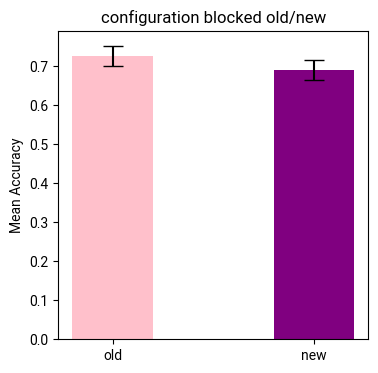

In [105]:
# %% Fig.1 (1.1-1.3) Figures start her.
# TODO: bookmarked figures
# est, mean accuracy for old vs new
# sys.exit()

for cond in conditions.keys():
    x = inference
    y = [oldnew_accuracy[cond]['old'], oldnew_accuracy[cond]['new']]

    # print(np.mean(y))
    w = 0.4

    fig, ax = plt.subplots(figsize=(4, 4))
    plt.bar(
        x,
        height=[np.mean(yi) for yi in y],
        yerr=[np.std(yi) / np.sqrt(np.size(yi)) for yi in y],
        width=w,
        capsize=7,
        color=['pink', 'purple'],
        zorder=-1,
    )
    plt.title(f'{cond} old/new')
    plt.ylabel("Mean Accuracy")
    # plt.ylim(0, 1)

    # Add significance stars above the bars, adjust height (y)

    p_value_oldnew = stats.ttest_ind(oldnew_accuracy[cond]['old'],
                                     oldnew_accuracy[cond]['new'], alternative='two-sided')[1]

    add_significance(ax, 0+w/2, 0 + w*2, max(np.mean(oldnew_accuracy[cond]['old'])+0.1,
                     np.mean(oldnew_accuracy[cond]['new'])), p_value_oldnew,
                     #num_bars=len(conditions)
                     )

    # if save_figs == True:
    #     plt.savefig(f'{figures_path}/{cond}_TEST.png',
    #                 dpi=1000, transparent=True)
    plt.show()


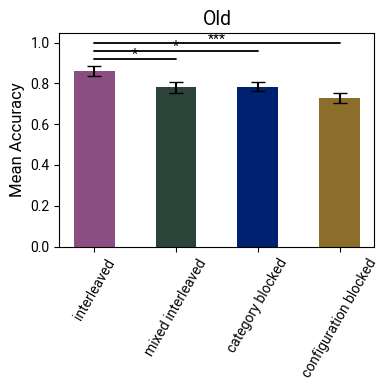

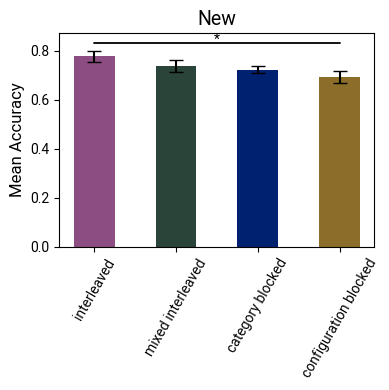

In [106]:

# %% Fig.2: Test, mean accuracy for old vs new for interleaved and blocked
for inf in inference:  # old/new
    # Updated to dynamically include all conditions
    x = list(conditions.keys())
    y = [oldnew_accuracy[cond][inf]
         for cond in x]  # shortened list comprehension

    w = 0.5  # Adjust width for closer bars

    fig, ax = plt.subplots(figsize=(4, 4))
    bars = plt.bar(
        x,
        height=[np.mean(yi) for yi in y],
        yerr=[np.std(yi) / np.sqrt(np.size(yi)) for yi in y],
        width=w,
        capsize=5,
        color=['#8C4E82', '#2a4439', '#002070', '#8C6E2A'],
        zorder=-1,
    )

    plt.title(f'{inf.capitalize()}', fontsize=14)
    plt.xticks(rotation=60)
    plt.ylabel("Mean Accuracy", fontsize=12)
    # plt.ylim(0, 1.2)
    plt.tight_layout()  # Ensure tight spacing

    # add significance bars
    for i, j in combinations(range(len(y)), 2):
        # Perform t-test
        p_value_cond = stats.ttest_ind(y[i], y[j], alternative='two-sided')[1]

        # Base height (highest bar of the two)
        base_height = max(np.mean(y[i]), np.mean(y[j]))+0.1

        # Add significance bar with dynamic spacing
        add_significance(ax, x1=i, x2=j, y_base=base_height,
                         p_value=p_value_cond,
                        #  num_bars=len(y)
                         )

    # Save with correct filename**
    if save_figs == True:
        plt.savefig(f'{figures_path}/{inf}.png', dpi=1000, transparent=True)
    plt.show()

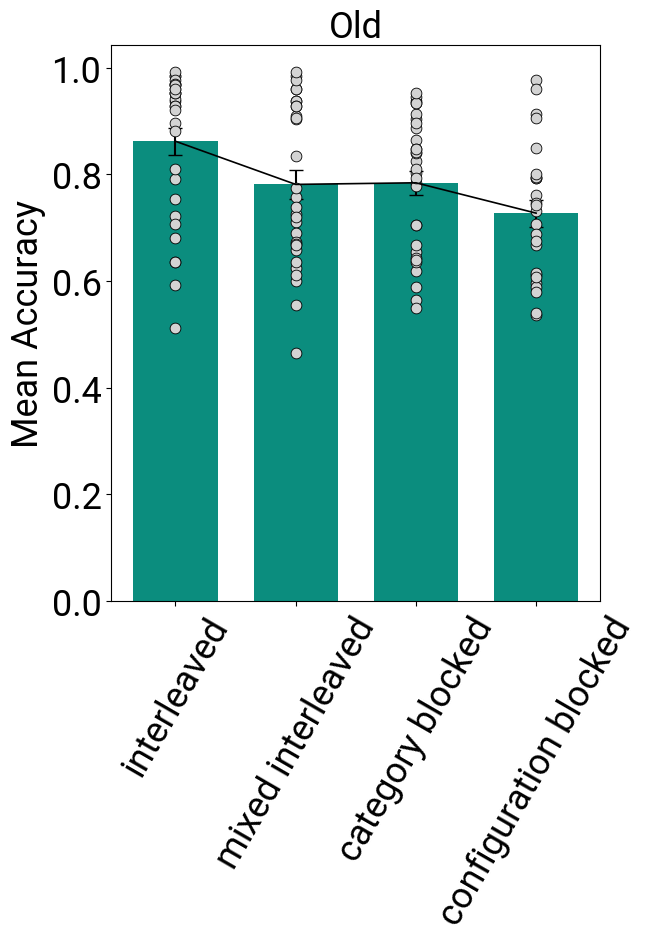

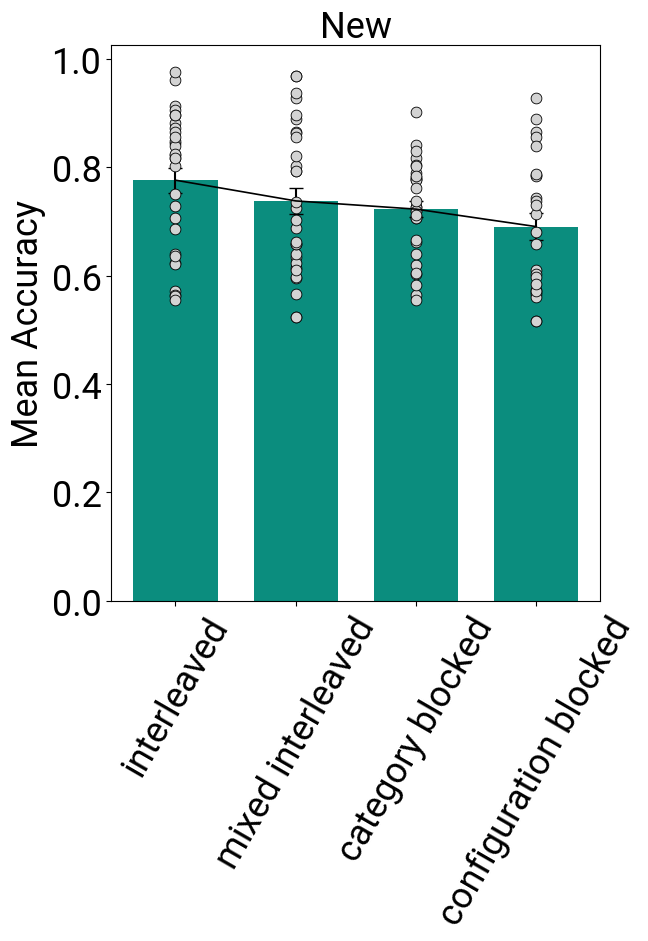

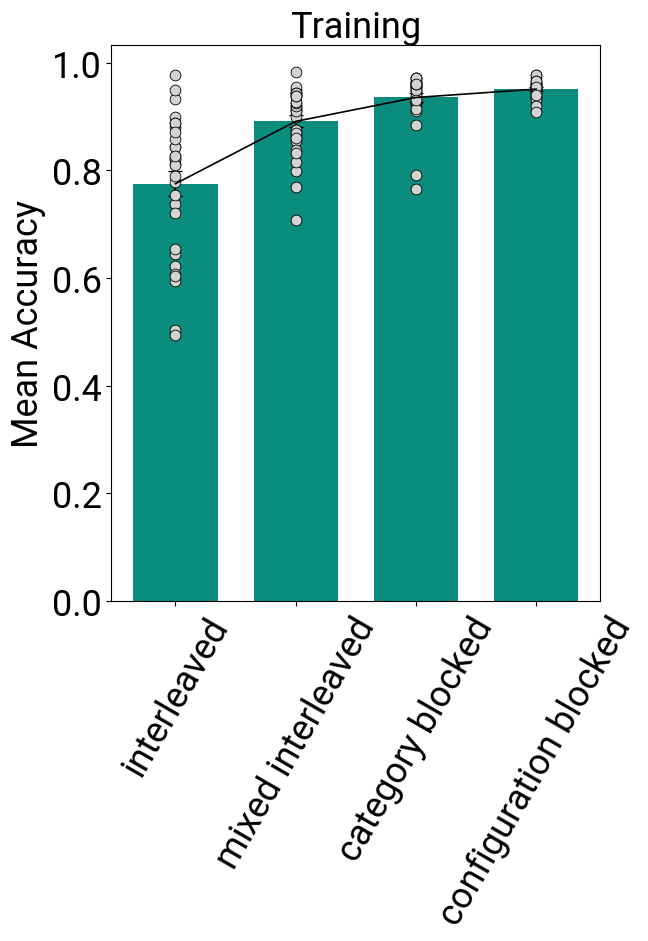

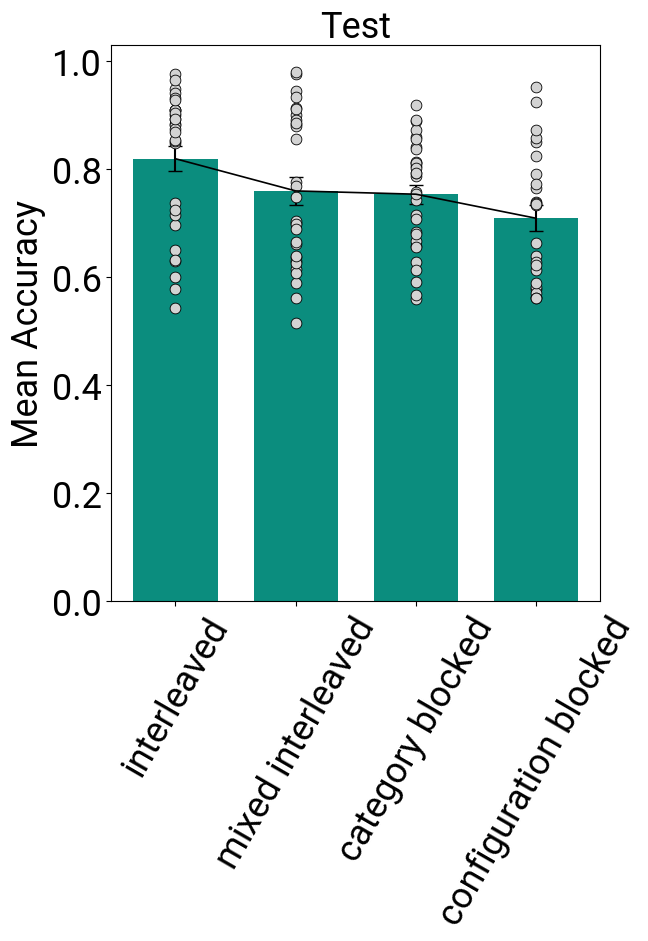

In [40]:
# MANUSCRIPT FIG1
fontsize = 26
plt.rcParams.update({
    "font.family": "Roboto",
    "font.size": fontsize,
})

figures = [('old_new', oldnew_accuracy, inference),
           ('training_test_conds', cond_accuracy, phases)]

ttest_results=[]
# %% Test, mean accuracy for old vs new for interleaved and blocked
for fig_name, accuracy_data, keys in figures:
    for phase in keys:  # old/new OR training/test (depending on keys)
        # Updated to dynamically include all conditions
        x = list(conditions.keys())
        y = [accuracy_data[cond][phase]
             for cond in x]  # shortened list comprehension

        w = 0.7  # Adjust width for closer bars

        fig, ax = plt.subplots(figsize=(7, 10))
        bars = plt.bar(
            x,
            height=[np.mean(yi) for yi in y],
            yerr=[np.std(yi) / np.sqrt(np.size(yi)) for yi in y],
            width=w,
            capsize=5,
            color="#0B8D7E",
            zorder=-1,
        )

        # Add participant means as vertically-aligned scatter on top of each bar
        for i, yi in enumerate(y):
            xi = bars[i].get_x() + bars[i].get_width() / 2  # bar center
            ax.scatter(
                np.full_like(np.asarray(yi), fill_value=xi, dtype=float),
                np.asarray(yi),
                s=60,
                facecolor="lightgrey",
                edgecolor="black",
                linewidth=0.6,
                alpha=1.0,
                zorder=1,
            )

        # Add line connecting the means of the bars
        bar_centers = [b.get_x() + b.get_width() / 2 for b in bars]
        bar_means = [np.mean(yi) for yi in y]
        ax.plot(
            bar_centers,
            bar_means,
            color="black",
            linewidth=1.2,
            zorder=2,
        )

        plt.title(f'{phase.capitalize()}', fontsize=fontsize, fontfamily='Roboto')
        plt.xticks(rotation=60, fontsize=fontsize, fontfamily='Roboto')
        plt.yticks(fontsize=fontsize, fontfamily='Roboto')
        plt.xlabel(plt.gca().get_xlabel(), fontsize=fontsize, fontfamily='Roboto')
        plt.ylabel("Mean Accuracy", fontsize=fontsize, fontfamily='Roboto')
        ax.tick_params(axis='both', labelsize=fontsize)
        # plt.ylim(0, 1.2)
        plt.tight_layout()  # Ensure tight spacing

        
        # add significance bars
        for i, j in combinations(range(len(y)), 2):
            cond_i = x[i]
            cond_j = x[j]

            t_value, p_value = stats.ttest_ind(
                y[i], y[j],
                alternative="two-sided"
            )

            ttest_results.append({
                "phase": phase,
                "comparison": f"{cond_i} vs {cond_j}",
                "t": t_value,
                "p": p_value,
            })

            comparison_key = (phase, cond_i, cond_j)
            # Perform t-test
            t_value_cond, p_value_cond = stats.ttest_ind(y[i], y[j], alternative='two-sided')
            p_value_by_condition[comparison_key].append(p_value_cond)
            t_value_by_condition[comparison_key].append(t_value_cond)

            # Base height (highest bar of the two)
            base_height = max(np.mean(y[i]), np.mean(y[j]))+0.4

            # Add significance bar with dynamic spacing
            # add_significance(ax, x1=i, x2=j, y_base=base_height,
            #                  p_value=p_value_cond,
            #                  bars=bars,
            #                 #  num_bars=len(y)
            #                  )


        # Save with correct filename
        if save_figs == True:
                out_path = Path(figures_path) / "Thesis" / f"{phase}.svg"
                out_path.parent.mkdir(parents=True, exist_ok=True) 
                plt.savefig(out_path, dpi=1000, transparent=True)
        plt.show()


In [74]:
ttest_results = pd.DataFrame(ttest_results)

ttest_results_display = ttest_results.copy()
ttest_results_display["t"] = ttest_results_display["t"].map(lambda v: f"{v:.2f}")
ttest_results_display["p"] = ttest_results_display["p"].map(
    lambda p: "< .001" if p < .001 else f"{p:.3f}"
)

ttest_results_display



,phase,comparison,t,p
0,old,interleaved vs mixed interleaved,2.15,0.036
1,old,interleaved vs category blocked,2.29,0.026
2,old,interleaved vs configuration blocked,3.69,< .001
3,old,mixed interleaved vs category blocked,-0.08,0.933
4,old,mixed interleaved vs configuration blocked,1.41,0.165
5,old,category blocked vs configuration blocked,1.66,0.102
6,new,interleaved vs mixed interleaved,1.12,0.269
7,new,interleaved vs category blocked,1.91,0.062
8,new,interleaved vs configuration blocked,2.48,0.016
9,new,mixed interleaved vs category blocked,0.52,0.606


In [8]:
# Linear regression across the 4 conditions
# import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf


figures = [('old_new', oldnew_accuracy, inference),
           ('training_test_conds', cond_accuracy, phases)]

condition_order = [
    "interleaved",
    "mixed interleaved",
    "category blocked",
    "configuration blocked",
]

# for fig_name, accuracy_data, keys in figures:
#     for phase in keys:
#         x = list(conditions.keys())
#         y = [accuracy_data[cond][phase] for cond in x]  # list of participant-accuracy vectors

#         # stack into long format: one row per (participant, condition)
#         X = np.concatenate([np.full(len(np.asarray(yi)), i) for i, yi in enumerate(y)])
#         Y = np.concatenate([np.asarray(yi) for yi in y])

#         # OLS: accuracy ~ linear trend over condition index (0,1,2,3) for interleaved and to -> category blocked
#         X = sm.add_constant(X, has_constant='raise')  # intercept. adds a column of ones
#         model = sm.OLS(Y, X).fit()

#         print(f"\n=== {fig_name} | {phase} ===")
#         print(f"slope (linear trend) = {model.params[1]:.6f}")
#         print(f"p-value (slope)      = {model.pvalues[1]:.6g}")
#         print(f"R^2                  = {model.rsquared:.4f}")
        # print(model.summary().tables[1])
    


# I can alternatively perform 4 one-way ANOVAa across the 4 conditions (between-groups) for each phase (old/new or training/test) 

anova_results = []

for fig_name, accuracy_data, keys in figures:
    for phase in keys:
        groups = [
            np.asarray(accuracy_data[cond][phase], dtype=float)
            for cond in condition_order
        ]
        groups = [g[~np.isnan(g)] for g in groups]

        F, p = stats.f_oneway(*groups)

        k = len(groups)
        N = sum(len(g) for g in groups)

        anova_results.append({
            "analysis": fig_name,
            "phase": phase,
            "test": "one-way ANOVA",
            "conditions_compared": " | ".join(condition_order),
            "n_conditions": k,
            "n_total": N,
            "df_between": k - 1,
            "df_within": N - k,
            "F": F,
            "p": f"= {p:.3f}",
        })

anova_results = pd.DataFrame(anova_results)

out_path = Path(figures_path) / "Thesis" / "anova_results.csv"
out_path.parent.mkdir(parents=True, exist_ok=True)
anova_results.to_csv(out_path, index=False)

anova_results


# The following is WRONG - because it reduces each condition into a single point.. That's not what I want 
# Add a spearman rank correlation between the condition index (0,1,2,3) and the participant accuracies
# s, per fig_name × phase
# for fig_name, accuracy_data, keys in figures:
#     for phase in keys:
#         conds = list(conditions.keys())
#         y = [accuracy_data[cond][phase] for cond in conds]  # list of participant-accuracy vectors per condition (interleaved/mixed_int/...etc.) )nd phase (old/new or training/test) 

#         # Compute mean accuracy per condition for the correlation
#         mean_accuracies = [np.mean(np.asarray(yi)) for yi in y]

#         # Spearman rank correlation between condition index (0,1,2,3) and mean accuracy
#         rho, p_value = stats.spearmanr(range(len(conds)), mean_accuracies)

#         print(f"\n=== {fig_name} | {phase} ===")
#         print(f"Spearman's rho = {rho}")
#         print(f"p-value       = {p_value}")


,analysis,phase,test,conditions_compared,n_conditions,n_total,df_between,df_within,F,p
0,old_new,old,one-way ANOVA,interleaved | mixed interleaved | category blo...,4,116,3,112,4.566220,= 0.005
1,old_new,new,one-way ANOVA,interleaved | mixed interleaved | category blo...,4,116,3,112,2.401738,= 0.071
2,training_test_conds,training,one-way ANOVA,interleaved | mixed interleaved | category blo...,4,116,3,112,30.573823,= 0.000
3,training_test_conds,test,one-way ANOVA,interleaved | mixed interleaved | category blo...,4,116,3,112,3.669689,= 0.014


In [7]:
# Two mixed two-way ANOVAs. Mixed because we have a between-subject factor (condition) and a within-subject factor (phase or inference).
# 1. condition × phase
# 2. condition × inference
#
# Requires Pingouin:
# %pip install pingouin

import numpy as np
import pandas as pd
import pingouin as pg
from pathlib import Path


condition_order = [
    "interleaved",
    "mixed interleaved",
    "category blocked",
    "configuration blocked",
]


def accuracy_to_long_format(accuracy_data, levels, within_factor):
    """
    Convert nested accuracy data into long format.

    Assumption:
    Within each condition, array position i represents the same participant
    across both levels of the within-subject factor.
    """
    rows = []

    for condition in condition_order:
        level_arrays = {
            level: np.asarray(accuracy_data[condition][level], dtype=float)
            for level in levels
        }

        lengths = {level: len(values) for level, values in level_arrays.items()}
        if len(set(lengths.values())) != 1:
            raise ValueError(
                f"Participant counts do not match across {within_factor} levels "
                f"for condition '{condition}': {lengths}"
            )

        n_participants = next(iter(lengths.values()))

        for participant_index in range(n_participants):
            # IDs must be unique across the between-subject conditions
            participant_id = f"{condition}_{participant_index}"

            for level in levels:
                rows.append({
                    "participant": participant_id,
                    "condition": condition,
                    within_factor: level,
                    "accuracy": level_arrays[level][participant_index],
                })

    data = pd.DataFrame(rows)

    data["condition"] = pd.Categorical(
        data["condition"],
        categories=condition_order,
        ordered=True,
    )

    data[within_factor] = pd.Categorical(
        data[within_factor],
        categories=levels,
        ordered=True,
    )

    # A participant must have a valid observation at both within-factor levels.
    complete_participants = (
        data.dropna(subset=["accuracy"])
        .groupby("participant", observed=True)[within_factor]
        .nunique()
    )

    complete_participants = complete_participants[
        complete_participants == len(levels)
    ].index

    return (
        data[data["participant"].isin(complete_participants)]
        .dropna(subset=["accuracy"])
        .reset_index(drop=True)
    )


analyses = [
    {
        "analysis": "condition_x_phase",
        "accuracy_data": cond_accuracy,
        "within_factor": "phase",
        "levels": ["training", "test"],
    },
    {
        "analysis": "condition_x_inference",
        "accuracy_data": oldnew_accuracy,
        "within_factor": "inference",
        "levels": ["old", "new"],
    },
]


anova_tables = []
long_format_data = {}

for analysis in analyses:
    analysis_name = analysis["analysis"]
    within_factor = analysis["within_factor"]

    data_long = accuracy_to_long_format(
        accuracy_data=analysis["accuracy_data"],
        levels=analysis["levels"],
        within_factor=within_factor,
    )

    long_format_data[analysis_name] = data_long

    # Mixed two-way ANOVA:
    # between-subject factor = condition
    # within-subject factor  = phase or inference
    anova = pg.mixed_anova(
        data=data_long,
        dv="accuracy",
        between="condition",
        within=within_factor,
        subject="participant",
        correction=True,
        effsize="np2",  # partial eta squared
    )

    anova.insert(0, "analysis", analysis_name)
    anova.insert(1, "within_factor", within_factor)

    anova_tables.append(anova)

    print(f"\n=== {analysis_name} ===")
    display(anova)


anova_results = pd.concat(anova_tables, ignore_index=True)

out_path = Path(figures_path) / "Thesis" / "two_way_anova_results.csv"
out_path.parent.mkdir(parents=True, exist_ok=True)
anova_results.to_csv(out_path, index=False)

anova_results


=== condition_x_phase ===


,analysis,within_factor,Source,SS,DF1,DF2,MS,F,p_unc,np2,eps
0,condition_x_phase,phase,condition,0.071047,3,112,0.023682,1.411059,2.433221e-01,0.036420,NaN
1,condition_x_phase,phase,phase,0.886986,1,112,0.886986,186.667997,1.323752e-25,0.625002,1.0
2,condition_x_phase,phase,Interaction,0.650719,3,112,0.216906,45.648374,2.383149e-19,0.550102,1.0



=== condition_x_inference ===


,analysis,within_factor,Source,SS,DF1,DF2,MS,F,p_unc,np2,eps
0,condition_x_inference,inference,condition,0.341487,3,112,0.113829,3.666473,1.450168e-02,0.089427,NaN
1,condition_x_inference,inference,inference,0.191379,1,112,0.191379,83.211286,3.503237e-15,0.426263,1.0
2,condition_x_inference,inference,Interaction,0.020794,3,112,0.006931,3.013724,3.305687e-02,0.074695,1.0


,analysis,within_factor,Source,SS,DF1,DF2,MS,F,p_unc,np2,eps
0,condition_x_phase,phase,condition,0.071047,3,112,0.023682,1.411059,2.433221e-01,0.036420,NaN
1,condition_x_phase,phase,phase,0.886986,1,112,0.886986,186.667997,1.323752e-25,0.625002,1.0
2,condition_x_phase,phase,Interaction,0.650719,3,112,0.216906,45.648374,2.383149e-19,0.550102,1.0
3,condition_x_inference,inference,condition,0.341487,3,112,0.113829,3.666473,1.450168e-02,0.089427,NaN
4,condition_x_inference,inference,inference,0.191379,1,112,0.191379,83.211286,3.503237e-15,0.426263,1.0
5,condition_x_inference,inference,Interaction,0.020794,3,112,0.006931,3.013724,3.305687e-02,0.074695,1.0


In [12]:
# Linear phase × condition interaction
# Tests whether the ordinal condition slope differs between training and test.

interaction_rows = []

for condition_score, condition in enumerate(condition_order):
    training = np.asarray(
        cond_accuracy[condition]["training"], dtype=float
    )
    test = np.asarray(
        cond_accuracy[condition]["test"], dtype=float
    )

    if len(training) != len(test):
        raise ValueError(
            f"Training and test lengths differ for {condition}: "
            f"{len(training)} versus {len(test)}"
        )

    # Retain participants who have both training and test values
    valid = np.isfinite(training) & np.isfinite(test)

    for participant_index in np.where(valid)[0]:
        interaction_rows.append({
            "participant": f"{condition}_{participant_index}",
            "condition": condition,
            "condition_score": condition_score,
            "accuracy_change": (
                training[participant_index] - test[participant_index]
            ),
        })

interaction_data = pd.DataFrame(interaction_rows)

# HC3 provides heteroskedasticity-robust standard errors
interaction_model = smf.ols(
    "accuracy_change ~ condition_score",
    data=interaction_data,
).fit(cov_type="HC3")

interaction_slope = interaction_model.params["condition_score"]
interaction_p = interaction_model.pvalues["condition_score"]
interaction_ci = interaction_model.conf_int().loc["condition_score"]

print("=== Phase × linear-condition interaction ===")
print(f"interaction slope = {interaction_slope:.6f}")
print(f"95% CI            = [{interaction_ci[0]:.6f}, "
      f"{interaction_ci[1]:.6f}]")
print(f"p-value           = {interaction_p:.6g}")
print(interaction_model.summary())

=== Phase × linear-condition interaction ===
interaction slope = 0.092165
95% CI            = [0.075722, 0.108607]
p-value           = 4.46344e-28
                            OLS Regression Results                            
Dep. Variable:        accuracy_change   R-squared:                       0.498
Model:                            OLS   Adj. R-squared:                  0.493
Method:                 Least Squares   F-statistic:                     120.7
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           1.38e-19
Time:                        18:53:39   Log-Likelihood:                 101.09
No. Observations:                 116   AIC:                            -198.2
Df Residuals:                     114   BIC:                            -192.7
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|    

/var/folders/fx/g0sdqwp52yxgfbdpddlbxx8c0000gr/T/ipykernel_23305/974593990.py:56: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/fx/g0sdqwp52yxgfbdpddlbxx8c0000gr/T/ipykernel_23305/974593990.py:56: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


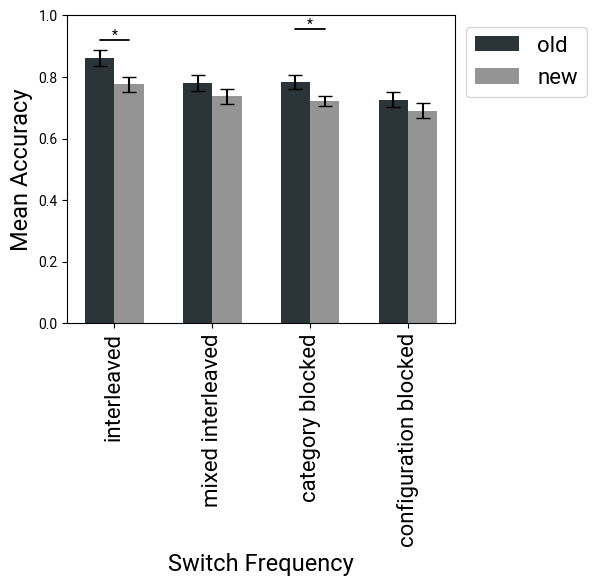

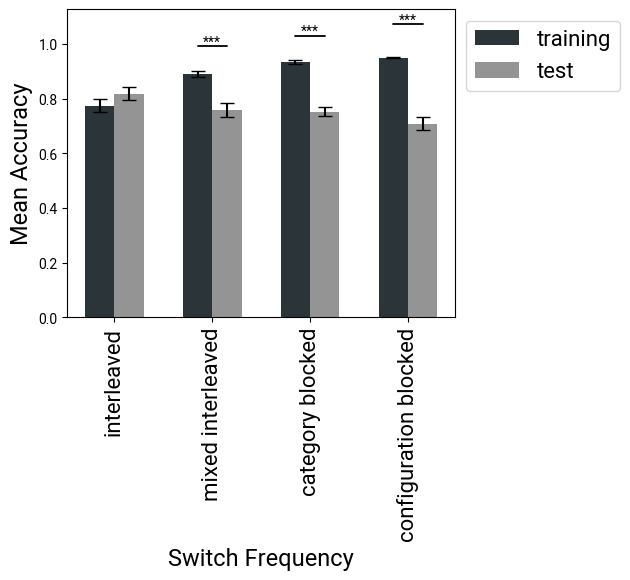

In [111]:
# %% Fig.3 & Fig 3.1: accuracies divided by Old and New and Training and Tests

figures = [('old_new', oldnew_accuracy, inference),
           ('training_test_conds', cond_accuracy, phases)]

for fig_name, accuracy_data, keys in figures:
    fig, ax = plt.subplots(figsize=(5, 4))
    x_axis = np.arange(len(conditions))
    width = 0.30

    # Add scores of all conditions
    y_data = [[accuracy_data[cond][key]
               for cond in conditions] for key in keys]
    colors = ['#2a3439', '#949494']
    bars = []

    for i, y in enumerate(y_data):
        bars.append(ax.bar(
            x_axis + i * width,
            height=[np.mean(yi) for yi in y],
            width=width,
            yerr=[np.std(yi) / np.sqrt(np.size(yi)) for yi in y],
            capsize=5,
            color=colors[i],
            zorder=-1,
        ))

    plt.xticks(x_axis + width / 2, conditions, fontsize=16, rotation=90)
    plt.xlabel("Switch Frequency", fontsize=17)
    plt.ylabel("Mean Accuracy", fontsize=17)

    # Set a base height above the highest bar (matching the "1 & 2" level from the function)
    base_height = max([max(np.mean(y[i]) for y in y_data) for i in range(
        len(conditions))]) + (0.01 if 'training' in keys else 0)
    sig_bar_width = width / 2  # Ensure width stays proportional

    # Add significance bars for within-condition comparisons (Old vs. New or Training vs. Test)
    for i in range(len(conditions)):
        # Perform t-test between the two groups within the same condition
        p_value = stats.ttest_ind(
            y_data[0][i], y_data[1][i], alternative='two-sided')[1]

        # Define positions: the significance bar should start and end in the middle of the two bars
        x1 = i + width / 2 - sig_bar_width
        x2 = i + width / 2 + sig_bar_width

        # Add significance bar at the lowest level
        add_significance(ax, x1, x2, base_height, p_value, len(conditions))

    ax.set_ylim(0, 1) if 'old_new' in fig_name else None

    lgd = ax.legend(bars, keys, bbox_to_anchor=(1, 1), fontsize=16)
    if save_figs:
        plt.savefig(f'{figures_path}/{fig_name}',
                    bbox_extra_artists=(lgd,), bbox_inches="tight", dpi=1000, transparent=True)
    fig.show()


/var/folders/fx/g0sdqwp52yxgfbdpddlbxx8c0000gr/T/ipykernel_23305/3083184483.py:184: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/fx/g0sdqwp52yxgfbdpddlbxx8c0000gr/T/ipykernel_23305/3083184483.py:184: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/fx/g0sdqwp52yxgfbdpddlbxx8c0000gr/T/ipykernel_23305/3083184483.py:184: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/fx/g0sdqwp52yxgfbdpddlbxx8c0000gr/T/ipykernel_23305/3083184483.py:184: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


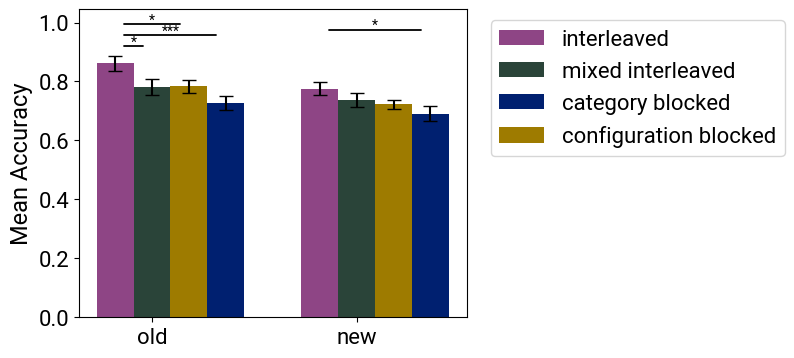

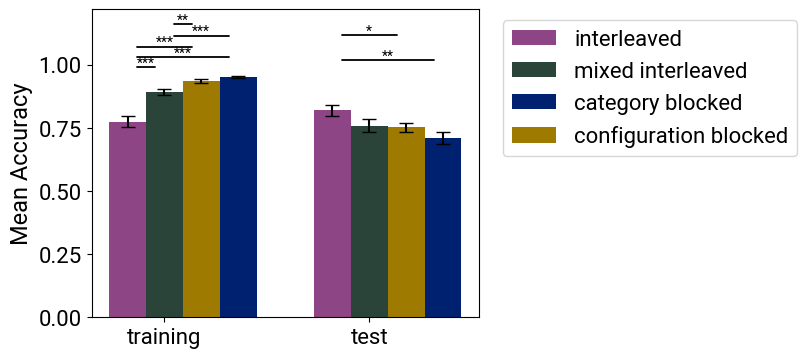

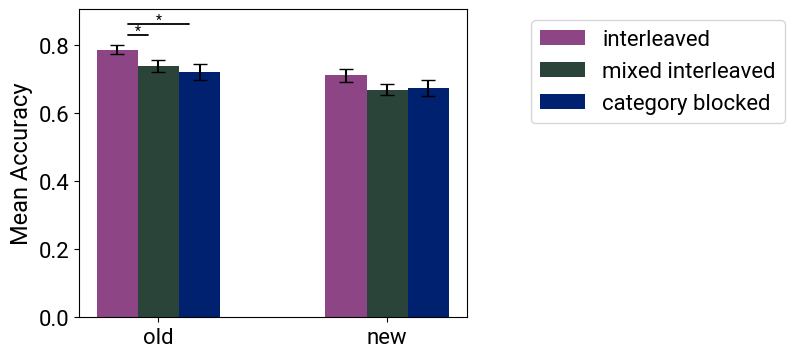

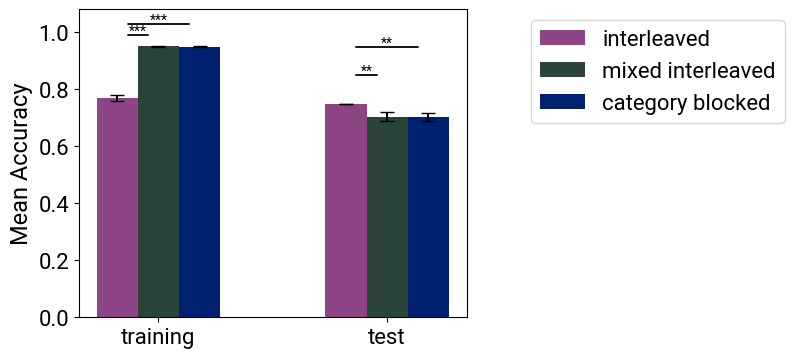

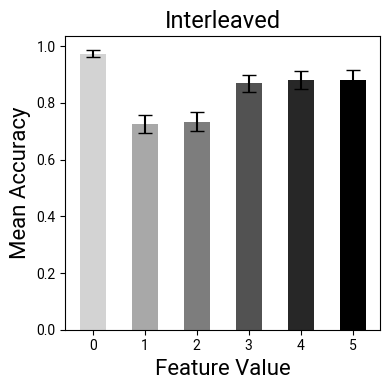

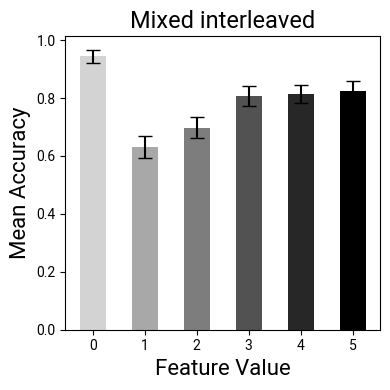

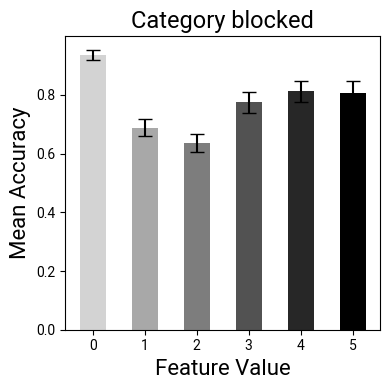

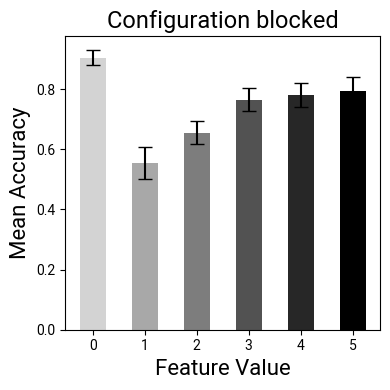

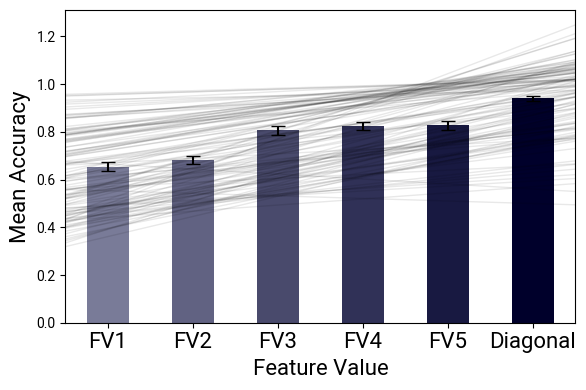

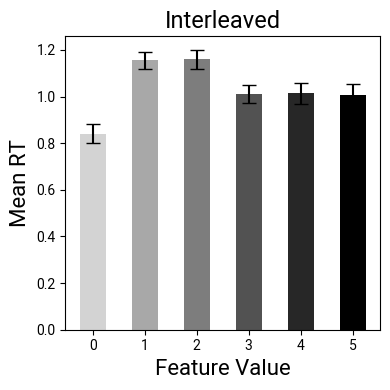

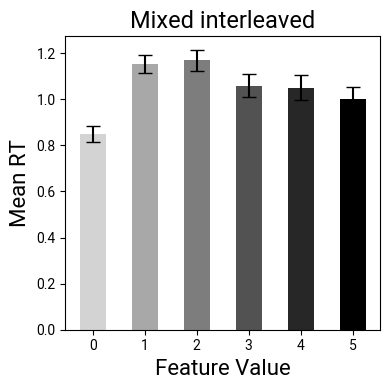

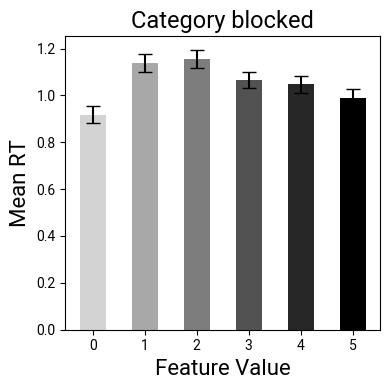

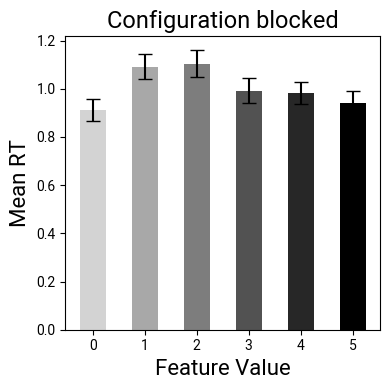

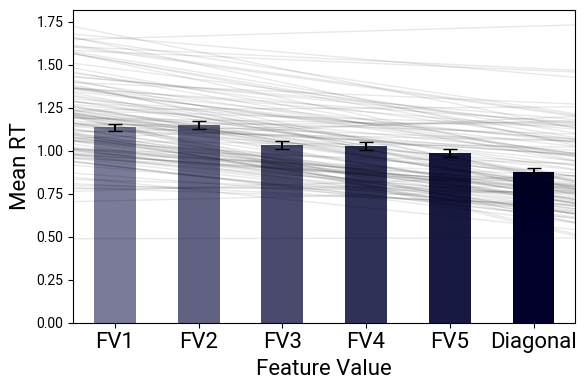

In [163]:
# %% Fig.4 & Fig. 4.1: Model and Behavioural. Old and New accuracies by conditions
# + Test _traiining by conditions
#

model_oldnew_accuracy = {'interleaved': {'old': [0.787, 0.014], 'new': [0.711, 0.019]},
                         'mixed interleaved': {'old': [0.739, 0.017], 'new': [0.669, 0.016]},
                         'configuration blocked': {'old': [0.722, 0.023], 'new': [0.674, 0.024]}}

model_testtrain_accuracy = {'interleaved': {'training': [0.77, 0.01], 'test': [0.749, 0.]},
                            'mixed interleaved': {'training': [0.950, 0.002], 'test': [0.704, 0.015]},
                            'configuration blocked': {'training': [0.949, 0.002], 'test': [0.703, 0.015]}}

# TODO: delete/comment out - for the same conditions without configuration blocked; for SAB
# oldnew_accuracy.pop('category blocked', None)
# cond_accuracy.pop('category blocked', None)
# rename_map = {
#     'interleaved': 'high',
#     'mixed interleaved': 'medium',
#     'configuration blocked': 'low'
# }
# dicts = [
#     oldnew_accuracy,
#     cond_accuracy,
#     model_oldnew_accuracy,
#     model_testtrain_accuracy
# ]
# oldnew_accuracy, cond_accuracy, model_oldnew_accuracy, model_testtrain_accuracy = [
#     {rename_map.get(k, k): v for k, v in d.items()}
#     for d in [oldnew_accuracy, cond_accuracy, model_oldnew_accuracy, model_testtrain_accuracy]
# ]
# end delete


figures = [
    ('test_blocked_int_old_new', oldnew_accuracy, inference),
    ('training_test', cond_accuracy, phases),
    ('model_old_new_acc', model_oldnew_accuracy, inference),
    ('model_training_test_acc', model_testtrain_accuracy, phases)
]

# num_bars = len(bar_positions)


for fig_name, accuracy_data, keys in figures:
    fig, ax = plt.subplots(figsize=(5, 4))
    x = [1, 2]
    x_axis = np.arange(len(x))
    # comment if want high, mid low
    if 'model' in fig_name:
        conditions_ = ['interleaved',
                       'mixed interleaved', 'configuration blocked']
        bar_positions = {
            "interleaved": -0.18,
            "mixed interleaved": 0,
            "configuration blocked": 0.18
        }
    else:
        conditions_ = ['interleaved', 'mixed interleaved',
                       'configuration blocked', 'category blocked']
        bar_positions = {
            "interleaved": -0.18,
            "mixed interleaved": 0,
            "category blocked": 0.18,
            "configuration blocked":0.36 ,
            
        }
    # uncomment if want high medium low
    # conditions_ = ['high',
    #                 'medium', 'low']
    # bar_positions = {
    #     "high": -0.18,
    #     "medium": 0,
    #     "low": 0.18
    # }

    comparisons = list(combinations(conditions_, 2))

    # Extract data
    # change names to high, mid, low if I want to recreate figs
    y_data = {group: [accuracy_data[group][key]
                      for key in keys] for group in conditions_}
    colors = {'interleaved': '#8E4585',
              'mixed interleaved': '#2a4439',
              'configuration blocked': '#002070',
              'category blocked': '#9E7B00',
            }
    bars = []

    for group in conditions_:
        if fig_name == 'test_blocked_int_old_new' or fig_name == 'training_test':  # behavioural results
            bars.append(ax.bar(
                x_axis + bar_positions[group],
                height=[np.mean(yi) for yi in y_data[group]],
                width=0.18,
                yerr=[np.std(yi) / np.sqrt(np.size(yi))
                      for yi in y_data[group]],
                capsize=5,
                color=colors[group],
                zorder=-1,
            ))
        elif fig_name == 'model_old_new_acc' or fig_name == 'model_training_test_acc':  # model results
            bars.append(ax.bar(
                x_axis + bar_positions[group],
                height=[yi[0] for yi in y_data[group]],
                width=0.18,
                yerr=[yi[1] for yi in y_data[group]],
                capsize=5,
                color=colors[group],
                zorder=-1,
            ))

    plt.xticks(x_axis, ['training', 'test']
               if 'training_test' in fig_name else inference, fontsize=17)
    # plt.xlabel("Switch Frequency", fontsize=17)
    plt.ylabel("Mean Accuracy", fontsize=17)
    # X-axis numbers (tick labels) size
    plt.tick_params(axis='x', labelsize=16)
    # Y-axis numbers (tick labels) size
    plt.tick_params(axis='y', labelsize=16)
    # plt.ylim(0, 1.1)

    # Adding significance bars for each x-axis position
    for i, key in enumerate(keys):
        for group1, group2 in comparisons:
            y1, y2 = y_data[group1][i], y_data[group2][i]

            # For model results (no datapoints), calculate t-statistic manually
            if fig_name == 'model_old_new_acc' or fig_name == 'model_training_test_acc':
                mean1, se1 = y1[0], y1[1]
                mean2, se2 = y2[0], y2[1]
                # Calculate the pooled standard error
                se_pooled = np.sqrt(se1**2 + se2**2)
                # Calculate the t-statistic
                t_stat = (mean1 - mean2) / se_pooled
                if fig_name == 'model_old_new_acc':
                    n1 = len(oldnew_accuracy[group1][key])
                    n2 = len(oldnew_accuracy[group2][key])
                elif fig_name == 'model_training_test_acc':
                    n1 = len(cond_accuracy[group1][key])
                    n2 = len(cond_accuracy[group2][key])
                # Calculate degrees of freedom
                df = n1 + n2 - 2
                # Calculate the p-value from the t-statistic. # Two-tailed p-value
                p_value = stats.t.sf(np.abs(t_stat), df) * 2
                base_height = max(mean1, mean2)
            else:  # for non model variables with data points (behavioural)
                p_value = stats.ttest_ind(y1, y2, alternative='two-sided')[1]
                base_height = max(np.mean(y1), np.mean(y2))

            # Calculate positions for the significance bar
            x1, x2 = x_axis[i] + bar_positions[group1], x_axis[i] + \
                bar_positions[group2]

            # reset and stack per x-axis position
            final_height = base_height + 0.1 * \
                comparisons.index((group1, group2))

            add_significance(ax, x1 + 0.18 / 4, x2 - 0.18 / 4,
                             final_height, p_value)
    # TODO: change to conditions, without "_"
    lgd = ax.legend(bars, conditions,
                    # title="Switch Frequency",
                    bbox_to_anchor=(1.85, 1),
                    fontsize=16, loc='upper right')

    if save_figs == True:
        # plt.savefig(f'{figures_path}/{fig_name}',
        #             bbox_extra_artists=(lgd,), bbox_inches="tight", dpi=1000, transparent=True)
        out_dir = f'{figures_path}/Thesis'
        os.makedirs(out_dir, exist_ok=True)

        fig_path = os.path.join(out_dir, f'{fig_name}.png')
        # plt.savefig(fig_path, format='pdf', transparent=True,
        #                 bbox_inches="tight",
        #                 bbox_extra_artists=(lgd,),
        #                 pad_inches=0.1
        #             )
        plt.savefig(fig_path,
            dpi=1000, transparent=True,
            bbox_inches="tight",
            bbox_extra_artists=(lgd,),
            pad_inches=0.1
        )
    fig.show()

# %% Fig 6: Feature Values. Four figures (1 for each group), each with 5 bars for FVs
x = features
result_type = ['Accuracy', 'RT']
for result in result_type:
    for group, numbers in conditions.items():
        # filter by groups
        mask = df_results['ppt_number'].apply(numbers)
        # apply filter of groups, and average the accuracy for each FV
        y = [df_results.loc[mask, f'{result}_FV{feature}']
             for feature in features]
        # print(group)
 
 
        w = 0.5  # Adjust width for closer bars
        fig, ax = plt.subplots(figsize=(4, 4))
        # ax.subplots(figsize=(4, 4))
        bars = ax.bar(
            x,
            height=[np.mean(yi) for yi in y],
            yerr=[np.std(yi) / np.sqrt(np.size(yi)) for yi in y],
            width=w,
            capsize=5,
            color=['#D3D3D3', '#A8A8A8', '#7D7D7D',
                   '#525252', '#272727', '#000000'],
            zorder=-1,
        )

        plt.title(f'{group.capitalize()}', fontsize=17)
        plt.xlabel("Feature Value", fontsize=16)
        plt.ylabel(f"Mean {result}", fontsize=16)
        # plt.ylim(0, 2)
        plt.tight_layout()  # Ensure tight spacingx

        # add significance bars
        # for i, j in combinations(range(len(y)), 2):
        #     # Perform t-test
        #     p_value_cond = stats.ttest_ind(y[i], y[j], alternative='two-sided')[1]

        #     # Base height (highest bar of the two)
        #     base_height = max(np.mean(y[i]), np.mean(y[j]))

        #     # Add significance bar with dynamic spacing
        #     add_significance(ax, x1=i, x2=j, y_base=base_height,
        #                      p_value=p_value_cond, num_bars=len(y))

        # Save with correct filename
        if save_figs == True:
            out_dir = f'{figures_path}/Thesis'
            os.makedirs(out_dir, exist_ok=True)

            fig_path = os.path.join(out_dir, f'{group}_{result}_FV.png')
            # plt.savefig(fig_path, format='pdf', transparent=True)
            plt.savefig(fig_path,
                dpi=1000, transparent=True,
                bbox_inches="tight",
                bbox_extra_artists=(lgd,),
                pad_inches=0.1
            )
        plt.show()

    # --- All conditions combined (average across all participants) ---
    x_reorganised = [1, 2, 3, 4, 5, 0] # FV0 is last, for diagonal
    x_pos = np.arange(len(x_reorganised))
    x_labels = ['FV1', 'FV2', 'FV3', 'FV4', 'FV5', 'Diagonal']
    y_all_reorganised = [df_results[f'{result}_FV{fv}'] for fv in x_reorganised]
    w = 0.5
    fig, ax = plt.subplots(figsize=(6, 4))
    bars = ax.bar(
        x_pos,
        height=[np.mean(yi) for yi in y_all_reorganised],
        yerr=[np.std(yi) / np.sqrt(np.size(yi)) for yi in y_all_reorganised],
        width=w,
        capsize=5,
        color=["#797B98", "#616282", "#494A6C",
            "#303157", "#181941", "#00002B"],
        zorder=-1,
    )

    # --- participant best-fit lines (very transparent) ---
    ax.set_xlim(-0.5, len(x_pos) - 0.5)
    x_line = np.linspace(ax.get_xlim()[0], ax.get_xlim()[1], 200)
    fv_cols = [f'{result}_FV{fv}' for fv in x_reorganised]

    for _, row in df_results[['ppt_number'] + fv_cols].iterrows():
        y = row[fv_cols].to_numpy(dtype=float)
        m = ~np.isnan(y)
        if m.sum() < 2:
            continue

        slope, intercept, *_ = stats.linregress(x_pos[m], y[m])
        ax.plot(
            x_line,
            intercept + slope * x_line,
            color="black",
            alpha=0.09,     # transparency
            linewidth=1.0,
            zorder=5,      # above bars
        )
        

    # plt.title('All Conditions', fontsize=17)
    plt.xlabel("Feature Value", fontsize=16)
    plt.xticks(x_pos, x_labels, fontsize=16)
    plt.ylabel(f"Mean {result}", fontsize=16)
    plt.tight_layout()

    if save_figs:
        out_dir = f'{figures_path}/Thesis'
        os.makedirs(out_dir, exist_ok=True)
        fig_path = os.path.join(out_dir, f'AllConditions_{result}_FV.png')
        plt.savefig(fig_path,
            dpi=1000, transparent=True,
            bbox_inches="tight",
            pad_inches=0.1
        )
    plt.show()
        # break


Slope test (participant-level): n=116; mean slope=0.0540; t=20.72; p=1.237e-40


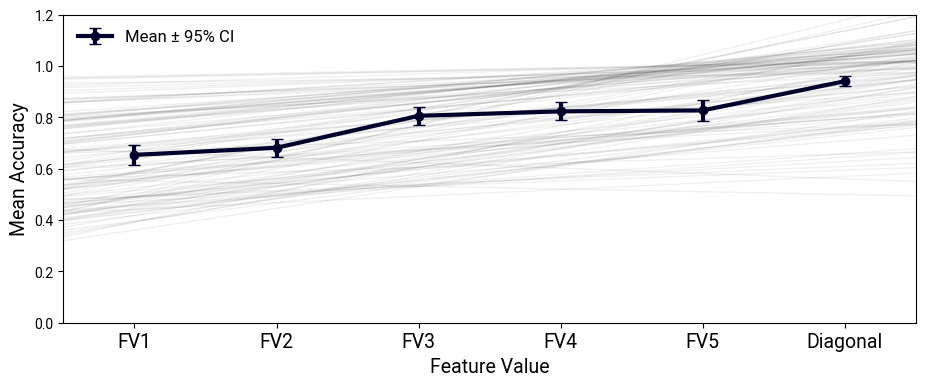

In [16]:
# %% FV Trend (All Participants): Individual Fits + Group Mean (95% CI) + Slope Distribution


# Order FV so Diagonal (FV0) is last/rightmost
fv_order = [1, 2, 3, 4, 5, 0]
x_pos = np.arange(len(fv_order))
x_labels = ["FV1", "FV2", "FV3", "FV4", "FV5", "Diagonal"]

fv_cols = [f"Accuracy_FV{fv}" for fv in fv_order]

# Wide: rows=participants, cols=FV levels in display order
wide = df_results[["ppt_number"] + fv_cols].set_index("ppt_number").dropna(how="all")

# Group mean + 95% CI at each FV
mean = wide.mean(axis=0)
n = wide.count(axis=0)
sem = wide.std(axis=0, ddof=1) / np.sqrt(n)
tcrit = stats.t.ppf(0.975, n - 1)
ci95 = tcrit * sem

# Participant slopes (best-fit line across the 6 ordered FV levels)
slopes = []
for _, row in wide.iterrows():
    y = row.to_numpy(dtype=float)
    m = ~np.isnan(y)
    if m.sum() < 2:
        continue
    slopes.append(stats.linregress(x_pos[m], y[m]).slope)
slopes = np.array(slopes, dtype=float   )

tt = stats.ttest_1samp(slopes, 0.0)
print(
    f"Slope test (participant-level): n={len(slopes)}; "
    f"mean slope={slopes.mean():.4f}; t={tt.statistic:.2f}; p={tt.pvalue:.4g}"
)

# ---- Plot ----
fig = plt.figure(figsize=(11, 4))

# Panel A: many individual best-fit lines (transparent) + group mean ± 95% CI
plt.xlim(-0.5, len(x_pos) - 0.5)
xmin, xmax = plt.xlim()
x_line = np.linspace(xmin, xmax, 200)

for _, row in wide.iterrows():
    y = row.to_numpy(dtype=float)
    m = ~np.isnan(y)
    if m.sum() < 2:
        continue
    lr = stats.linregress(x_pos[m], y[m])
    plt.plot(
        x_line,
        lr.intercept + lr.slope * x_line,
        color="black",
        alpha=0.06,      
        linewidth=1.0,
        zorder=5,
    )

plt.errorbar(
    x_pos,
    mean.to_numpy(),
    yerr=ci95.to_numpy(),
    fmt="o-",
    color="#00002B",
    linewidth=3,
    markersize=6,
    capsize=4,
    zorder=10,
    label="Mean ± 95% CI",
)

plt.xticks(x_pos, x_labels, fontsize=14)
plt.xlabel("Feature Value", fontsize=14)
plt.ylabel("Mean Accuracy", fontsize=14)
plt.ylim(0, 1.2)
plt.legend(frameon=False, fontsize=12, loc="best")



if save_figs:
    out_dir = f"{figures_path}/Thesis"
    os.makedirs(out_dir, exist_ok=True)
    fig_path = os.path.join(out_dir, "FV_trend_meanCI_spaghetti_slopeDist.png")
    plt.savefig(fig_path, dpi=1000, transparent=True, bbox_inches="tight", pad_inches=0.1)

plt.show()


Slope test (participant-level): n=116; mean slope=0.0540; t=20.72; p=1.237e-40


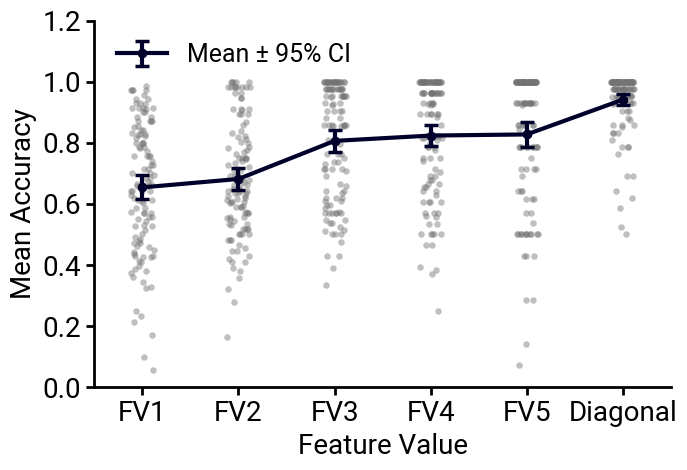

In [20]:
# Figure 2B: FV Trend by Condition 

# Order FV so Diagonal (FV0) is last/rightmost
fv_order = [1, 2, 3, 4, 5, 0]
x_pos = np.arange(len(fv_order))
x_labels = ["FV1", "FV2", "FV3", "FV4", "FV5", "Diagonal"]
font_size = 20

fv_cols = [f"Accuracy_FV{fv}" for fv in fv_order]

# Wide: rows=participants, cols=FV levels in display order
wide = df_results[["ppt_number"] + fv_cols].set_index("ppt_number").dropna(how="all")

# Group mean + 95% CI at each FV
mean = wide.mean(axis=0)
n = wide.count(axis=0)
sem = wide.std(axis=0, ddof=1) / np.sqrt(n)
tcrit = stats.t.ppf(0.975, n - 1)
ci95 = tcrit * sem

# Participant slopes
slopes = []
for _, row in wide.iterrows():
    y = row.to_numpy(dtype=float)
    m = ~np.isnan(y)
    if m.sum() < 2:
        continue
    slopes.append(stats.linregress(x_pos[m], y[m]).slope)

slopes = np.array(slopes, dtype=float)

tt = stats.ttest_1samp(slopes, 0.0)
print(
    f"Slope test (participant-level): n={len(slopes)}; "
    f"mean slope={slopes.mean():.4f}; t={tt.statistic:.2f}; p={tt.pvalue:.4g}"
)

# ---- Plot ----
plt.rcParams.update({
    "font.family": "Roboto",
    "font.weight": "medium",
    "axes.labelweight": "medium",
    "svg.fonttype": "none",  # keeps text editable in Illustrator
})

fig, ax = plt.subplots(figsize=(7.0, 4.8))

# Participant-level dots at each FV level
rng = np.random.default_rng(7)

for i, col in enumerate(fv_cols):
    y = wide[col].dropna().to_numpy(dtype=float)
    jitter = rng.uniform(-0.12, 0.12, size=len(y))

    ax.scatter(
        np.full(len(y), x_pos[i]) + jitter,
        y,
        s=22,
        color="0.45",
        alpha=0.45,
        linewidths=0,
        zorder=5,
    )

# Group mean ± 95% CI
ax.errorbar(
    x_pos,
    mean.to_numpy(),
    yerr=ci95.to_numpy(),
    fmt="o-",
    color="#00002B",
    linewidth=3,
    markersize=6,
    capsize=5,
    capthick=2.5,
    zorder=10,
    label="Mean ± 95% CI",
)

ax.set_xlim(-0.5, len(x_pos) - 0.5)
ax.set_ylim(0, 1.2)

ax.set_xticks(x_pos)
ax.set_xticklabels(x_labels, fontsize=font_size, fontweight="medium")

ax.set_xlabel("Feature Value", fontsize=font_size, fontweight="medium")
ax.set_ylabel("Mean Accuracy", fontsize=font_size, fontweight="medium")

ax.tick_params(axis="both", labelsize=font_size, width=2, length=6)

for tick in ax.get_yticklabels():
    tick.set_fontweight("medium")

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

for spine in ["bottom", "left"]:
    ax.spines[spine].set_linewidth(2)

ax.legend(
    frameon=False,
    loc="upper left",
    prop={"family": "Roboto", "weight": "medium", "size": 18},
)

fig.tight_layout()

if save_figs:
    out_dir = f"{figures_path}/Thesis"
    os.makedirs(out_dir, exist_ok=True)

    fig_path = os.path.join(out_dir, "FV_trend_meanCI_participantDots.svg")
    fig.savefig(
        fig_path,
        transparent=True,
        bbox_inches="tight",
        pad_inches=0.1,
    )

plt.show()




In [187]:
# Correlation between FV and accruacty across all conditions and participants
# This is to test whether there is a linear relationship between feature value and accuracy, across all conditions

## %% FV effect on mean accuracy (Fig 6 means): Diagonal treated as "largest"

# Display order (Diagonal last)
fv_order = [1, 2, 3, 4, 5, 0]

# Ordinal scores for correlation (Diagonal highest)
fv_score = {1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 0: 6}

# Build long df: one row per (participant, FV)
rows = []
for fv in fv_order:
    col = f"Accuracy_FV{fv}"
    if col not in df_results.columns:
        raise KeyError(f"Missing column: {col}")
    tmp = df_results[["ppt_number", col]].rename(columns={col: "mean_accuracy"}).copy()
    tmp["fv"] = fv
    tmp["fv_score"] = fv_score[fv]
    rows.append(tmp)

# now we have a long df with columns: ppt_number, mean_accuracy, fv and fv_score (renamed fv)
df_long = pd.concat(rows, ignore_index=True).dropna(subset=["mean_accuracy"])

# 1) "Correlation" (ordered categorical): Spearman per participant, then test across participants
rhos = []
for ppt, sub in df_long.groupby("ppt_number"):
    if sub["fv_score"].nunique() < 3:
        continue
    rho, _ = stats.spearmanr(sub["fv_score"], sub["mean_accuracy"])
    if np.isfinite(rho):
        rhos.append(rho)

rhos = np.array(rhos, dtype=float)
z = np.arctanh(np.clip(rhos, -0.999999, 0.999999))
tt = stats.ttest_1samp(z, 0.0)

print(
    "Spearman (ordered FV; Diagonal highest): "
    f"n={len(rhos)}, mean rho={np.tanh(z.mean()):.3f}, t={tt.statistic:.2f}, p={tt.pvalue:.4g}"
)

# 2) Categorical effect (no ordering): Friedman test across the 6 FV levels (within-subject)
wide = df_long.pivot(index="ppt_number", columns="fv", values="mean_accuracy")[fv_order].dropna()
chi2, p = stats.friedmanchisquare(*[wide[fv] for fv in fv_order])
n, k = wide.shape
kendalls_w = chi2 / (n * (k - 1))

print(
    f"Friedman (categorical FV effect): n={n}, chi2={chi2:.2f}, p={p:.4g}, Kendall's W={kendalls_w:.3f}"
)



Spearman (ordered FV; Diagonal highest): n=116, mean rho=0.775, t=11.18, p=4.323e-20
Friedman (categorical FV effect): n=116, chi2=255.56, p=3.532e-53, Kendall's W=0.441


In [188]:
# %% LME on participant FV means: accuracy ~ FV + (FV | participant)
import re
import statsmodels.formula.api as smf

result = "Accuracy"

# FV is ordinal: 1 < 2 < 3 < 4 < 5 < Diagonal(FV0)
fv_ordinal = {1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 0: 6}

# Build long df from df_results means
fv_cols = [c for c in df_results.columns if c.startswith(f"{result}_FV")]
df_lme = (
    df_results[["ppt_number"] + fv_cols]
    .melt(id_vars="ppt_number", var_name="fv_col", value_name="accuracy")
    .dropna(subset=["ppt_number", "accuracy"])
)
df_lme["ppt_number"] = df_lme["ppt_number"].astype(int)
df_lme["fv_raw"] = df_lme["fv_col"].str.extract(r"FV(\d+)").astype(int)
df_lme["FV"] = df_lme["fv_raw"].map(fv_ordinal).astype(float)

# I can mean-center FV for a sensible intercept + better stability (still the same model structure)
# df_lme["FV"] = df_lme["FV"] - df_lme["FV"].mean()

# accuracy ~ FV + (FV | participant)
m = smf.mixedlm(
    "accuracy ~ FV",
    df_lme,
    groups=df_lme["ppt_number"],
    re_formula="~FV",
).fit(reml=False, method="lbfgs")

print(m.summary())


          Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  accuracy
No. Observations:  696      Method:              ML      
No. Groups:        116      Scale:               0.0207  
Min. group size:   6        Log-Likelihood:      260.2012
Max. group size:   6        Converged:           Yes     
Mean group size:   6.0                                   
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept       0.600    0.018 33.326 0.000  0.565  0.635
FV              0.054    0.003 16.301 0.000  0.048  0.060
Group Var       0.020    0.055                           
Group x FV Cov -0.001    0.012                           
FV Var          0.000    0.003                           



/Users/elnagar/miniforge3/envs/cvlearn/lib/python3.14/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


In [11]:
# Repeated-measures ANOVA on participant FV means: accuracy ~ FV (within-subject)
from statsmodels.stats.anova import AnovaRM
import pandas as pd

result = "Accuracy"

fv_cols = [c for c in df_results.columns if c.startswith(f"{result}_FV")]

df_anova = (
    df_results[["ppt_number"] + fv_cols]
    .melt(id_vars="ppt_number", var_name="fv_col", value_name="accuracy")
    .dropna(subset=["ppt_number", "accuracy"])
)

df_anova["ppt_number"] = df_anova["ppt_number"].astype(int)
df_anova["fv_raw"] = df_anova["fv_col"].str.extract(r"FV(\d+)").astype(int)

fv_labels = {
    1: "FV1",
    2: "FV2",
    3: "FV3",
    4: "FV4",
    5: "FV5",
    0: "Diagonal"
}

df_anova["FV"] = df_anova["fv_raw"].map(fv_labels)

df_anova["FV"] = pd.Categorical(
    df_anova["FV"],
    categories=["FV1", "FV2", "FV3", "FV4", "FV5", "Diagonal"],
    ordered=True
)

anova = AnovaRM(
    data=df_anova,
    depvar="accuracy",
    subject="ppt_number",
    within=["FV"]
).fit()

anova_table = anova.anova_table
anova_table

,F Value,Num DF,Den DF,Pr > F
FV,64.175924,5.0,575.0,3.428106e-53


In [14]:
# Post-hoc pairwise comparisons between FV levels with FDR correction

from itertools import combinations
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests
import pandas as pd

# Make sure this uses the same df_anova from the repeated-measures ANOVA
# Columns: ppt_number, FV, accuracy

fv_order = ["FV1", "FV2", "FV3", "FV4", "FV5", "Diagonal"]

# Wide format: one row per participant, one column per FV level
df_wide = df_anova.pivot(
    index="ppt_number",
    columns="FV",
    values="accuracy"
)

posthoc_results = []

for fv1, fv2 in combinations(fv_order, 2):
    pair_df = df_wide[[fv1, fv2]].dropna()

    t_stat, p_val = ttest_rel(pair_df[fv1], pair_df[fv2])

    posthoc_results.append({
        "comparison": f"{fv1} vs {fv2}",
        "n": len(pair_df),
        "t": t_stat,
        "p_uncorrected": p_val
    })

posthoc_fv = pd.DataFrame(posthoc_results)

# Correct for multiple comparisons
# posthoc_fv["p_fdr"] = multipletests(
#     posthoc_fv["p_uncorrected"],
#     method="fdr_bh"
# )[1]

# Optional manuscript-style formatting
# posthoc_fv["p_report"] = posthoc_fv["p_fdr"].apply(
#     lambda p: "< .001" if p < .001 else f"= {p:.3f}".replace("0.", ".")
# )

posthoc_fv["t"] = posthoc_fv["t"].round(2)

posthoc_fv


,comparison,n,t,p_uncorrected
0,FV1 vs FV2,116,-1.00,3.185584e-01
1,FV1 vs FV3,116,-7.04,1.492386e-10
2,FV1 vs FV4,116,-8.09,6.811758e-13
3,FV1 vs FV5,116,-7.23,5.679287e-11
4,FV1 vs Diagonal,116,-15.06,5.718932e-29
5,FV2 vs FV3,116,-9.04,4.503967e-15
6,FV2 vs FV4,116,-8.50,7.803779e-14
7,FV2 vs FV5,116,-7.47,1.707885e-11
8,FV2 vs Diagonal,116,-14.27,3.359382e-27
9,FV3 vs FV4,116,-1.96,5.295563e-02


In [181]:
# %% GLMM (Binomial): Trial Accuracy ~ Ordered FV (Diagonal Highest) + (1 + FV | ppt)

import glob
import numpy as np
import pandas as pd
import scipy.io
from tqdm import tqdm

# --- use the same participants that survived your exclusions (df_results after filtering) ---
included_ppts = sorted(df_results["ppt_number"].dropna().astype(int).unique())

# --- map configuration (1..36) -> feature_value (0..5), same as your grid logic ---
config_to_fv = {}
combination_number = 0
for y in range(1, 7):
    for x in range(1, 7):
        combination_number += 1
        config_to_fv[combination_number] = abs(x - y)

# Order for the journal plot: FV1..FV5, then Diagonal(FV0) last/highest
fv_order = [1, 2, 3, 4, 5, 0]
fv_to_score = {1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 0: 6}  # Diagonal treated as largest

def _to_float(v):
    # robust scalar extraction from matlab-ish cells
    if isinstance(v, np.ndarray):
        if v.size == 0:
            return np.nan
        v = np.squeeze(v)
        if np.size(v) == 1:
            v = v.item()
        else:
            v = np.ravel(v)[0]
    if isinstance(v, (bytes, bytearray)):
        v = v.decode("utf-8")
    if isinstance(v, str):
        v = v.strip().replace("[", "").replace("]", "")
        if v == "" or v.lower() == "nan":
            return np.nan
    try:
        return float(v)
    except Exception:
        return np.nan

rows = []
for ppt in tqdm(included_ppts, desc="Loading test trials"):
    test_files = glob.glob(f"{base_directory}sbj{ppt}/sbj{ppt}Test*.mat")
    if not test_files:
        continue

    mat = scipy.io.loadmat(test_files[0])
    df = pd.DataFrame(mat["Results"][0][0][0][0]).copy()

    # Keep only what we need
    for col in ["Feedback", "RT", "TrialLost", "Configuration"]:
        df[col] = df[col].apply(_to_float)

    # Match your preprocessing
    df = df[(df["RT"] >= 0.3) & (df["TrialLost"] == 0)]
    df = df.dropna(subset=["Feedback", "Configuration"])

    df["Configuration"] = df["Configuration"].astype(int)
    df["feature_value"] = df["Configuration"].map(config_to_fv)
    df = df.dropna(subset=["feature_value"])

    df["feature_value"] = df["feature_value"].astype(int)
    df["fv_score"] = df["feature_value"].map(fv_to_score).astype(int)  # 1..6 (Diagonal=6)
    df["fv_score"] = pd.Categorical(df["fv_score"], ordered=True, categories=[1, 2, 3, 4, 5, 6])

    df["Feedback"] = df["Feedback"].astype(int)
    df["ppt_number"] = ppt

    rows.append(df[["ppt_number", "Feedback", "fv_score"]])

df_glmm = pd.concat(rows, ignore_index=True).dropna()

# numeric, centered predictor for the model slope
df_glmm["fv_score_num"] = df_glmm["fv_score"].astype(int)
df_glmm["fv_score_c"] = df_glmm["fv_score_num"] - df_glmm["fv_score_num"].mean()

print("Trials:", len(df_glmm), "Participants:", df_glmm["ppt_number"].nunique())

# --- Fit logistic mixed model ---
# Uses statsmodels' BinomialBayesMixedGLM (variational Bayes GLMM).
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

vc = {
    "ppt_intercept": "0 + C(ppt_number)",
    "ppt_slope": "0 + C(ppt_number):fv_score_c",
}

model = BinomialBayesMixedGLM.from_formula("Feedback ~ fv_score_c", vc, data=df_glmm)
res = model.fit_vb()
print(res.summary())

# Optional: odds ratio per +1 FV step (approx)
if hasattr(res, "fe_mean") and hasattr(res, "fe_sd"):
    fe_names = model.exog_names
    j = fe_names.index("fv_score_c")
    beta = res.fe_mean[j]
    se = res.fe_sd[j]
    OR = float(np.exp(beta))
    CI = np.exp(beta + np.array([-1, 1]) * 1.96 * se)
    print(f"OR per +1 FV step (approx): {OR:.3f} (95% approx CI {CI[0]:.3f}, {CI[1]:.3f})")


Loading test trials: 100%|██████████| 116/116 [00:00<00:00, 185.74it/s]


Trials: 28883 Participants: 116
                 Binomial Mixed GLM Results
              Type Post. Mean Post. SD   SD  SD (LB) SD (UB)
------------------------------------------------------------
Intercept        M     1.7139   0.0152                      
fv_score_c       M     0.5732   0.0093                      
ppt_intercept    V     0.1279   0.0655 1.136   0.997   1.295
ppt_slope        V    -0.8080   0.0657 0.446   0.391   0.508
Parameter types are mean structure (M) and variance
structure (V)
Variance parameters are modeled as log standard deviations
OR per +1 FV step (approx): 1.774 (95% approx CI 1.742, 1.806)


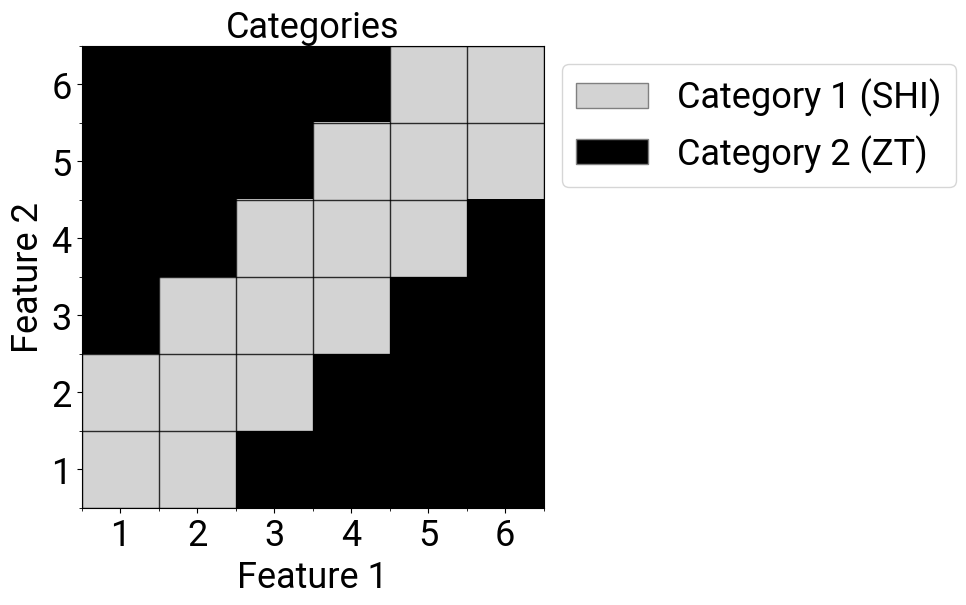

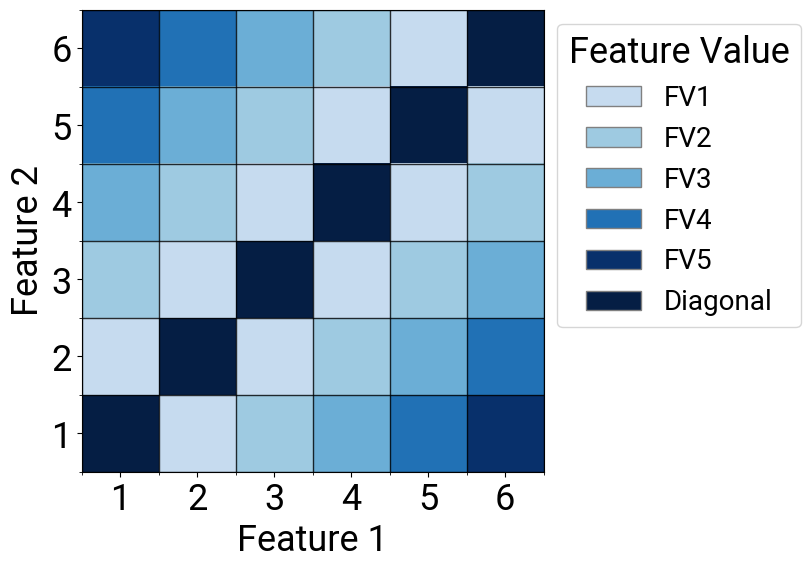

In [24]:
# %% Figure 7: Visualise FV grid
font_size = 26

plt.rcParams.update({
    "font.family": "Roboto",
    "font.size": font_size,
    "svg.fonttype": "none",
})

feature_colors = ["#051E44", "#C6DBEF", "#9ECAE1", "#6BAED6", "#2171B5", "#08306B"]

# Generate matrix data
matrix = np.arange(1, 37).reshape(6, 6)
x_labels = [str(x) for x in range(1, 7)]
y_labels = [str(y) for y in range(1, 7)]

# Create figure generator
for fig_num in range(2):
    # Create color matrix based on figure type
    if fig_num == 0:  # Category figure
        color_matrix = np.full(matrix.shape, '#D3D3D3')
        for i in range(6):
            for j in range(6):
                if matrix[i, j] in ZT_configs:
                    color_matrix[i, j] = '#000000'
    else:  # Feature value figure
        color_matrix = np.empty(matrix.shape, dtype=object)
        for i in range(6):
            for j in range(6):
                feature_value = abs((j+1) - (i+1))  # Calculate |x - y|
                color_matrix[i, j] = feature_colors[feature_value]

    # Create plot
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow([[plt.cm.colors.to_rgb(cell) for cell in row] for row in color_matrix],
              origin='lower',
              extent=[0.5, 6.5, 0.5, 6.5])

    # Add combination numbers
    # for i in range(6):
    #     for j in range(6):
    #         text_color = 'white' if (
    #             fig_num == 0 and matrix[i, j] in ZT_configs) else 'black'
    #         ax.text(j+1, i+1, str(matrix[i, j]),
    #                 ha='center', va='center',
    #                 fontsize=18, color=text_color)

    # Add grid borders
    # Set major ticks (label positions) at cell centers
    ax.set_xticks(np.arange(1, 7))
    ax.set_yticks(np.arange(1, 7))

    # Set minor ticks (border positions) at cell edges
    ax.set_xticks(np.arange(0.5, 7, 1), minor=True)
    ax.set_yticks(np.arange(0.5, 7, 1), minor=True)

    # Create borders using minor ticks
    ax.grid(which='minor', color='black',
            linestyle='-', linewidth=1, alpha=0.8)

    # Axis labels
    ax.set_xlabel('Feature 1', fontsize=font_size, fontfamily='Roboto')
    ax.set_ylabel('Feature 2', fontsize=font_size, fontfamily='Roboto')
    ax.set_title('Categories' if fig_num == 0 else None, fontsize=font_size, fontfamily='Roboto')
    ax.tick_params(axis='x', labelsize=font_size)
    ax.tick_params(axis='y', labelsize=font_size)   
    # Add legend for category figure
    if fig_num == 0:
        legend_elements = [
            mpatches.Patch(facecolor='#D3D3D3', edgecolor='gray',
                           label='Category 1 (SHI)'),
            mpatches.Patch(facecolor='#000000', edgecolor='gray',
                           label='Category 2 (ZT)')
        ]
        ax.legend(handles=legend_elements,
                  loc='upper left',
                  bbox_to_anchor=(1, 1), fontsize=font_size)
    else:
        fv_labels = ['FV1', 'FV2', 'FV3', 'FV4', 'FV5', 'Diagonal']  # lightest -> darkest
        feature_colors = [ "#C6DBEF", "#9ECAE1", "#6BAED6", "#2171B5", "#08306B", "#051E44"]
        legend_elements = [
            mpatches.Patch(facecolor=c, edgecolor='gray', label=f'{lab}')
            for lab, c in zip(fv_labels, feature_colors)
        ]
        ax.legend(handles=legend_elements, title='Feature Value',
                loc='upper left', bbox_to_anchor=(1, 1), fontsize=20, title_fontsize=font_size)

    # Save figures
    fname = "Categories_Values.png" if fig_num == 0 else "Feature_Value.png"
    plt.savefig(f'{figures_path}/{fname}',
                bbox_inches='tight', dpi=300, transparent=True)
    plt.show()
    # plt.close()  # Close figure to free memory


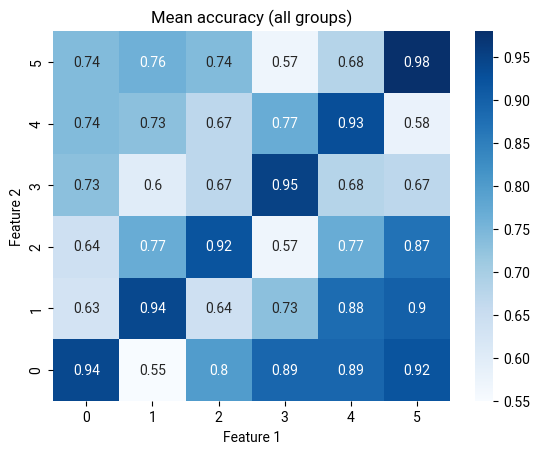

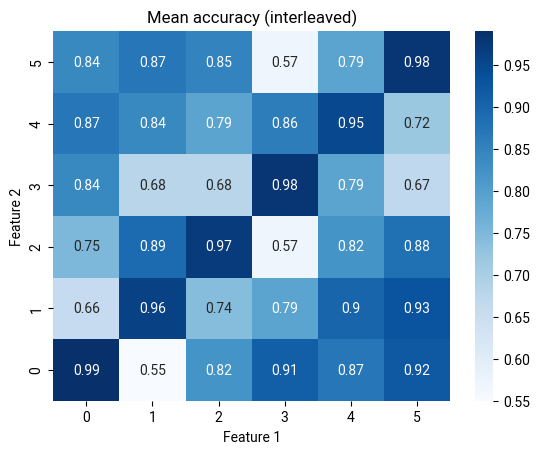

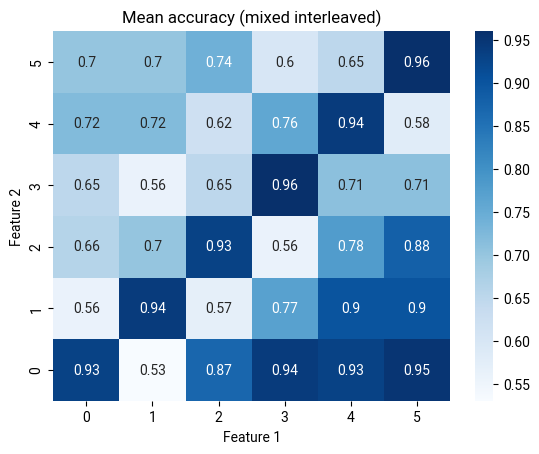

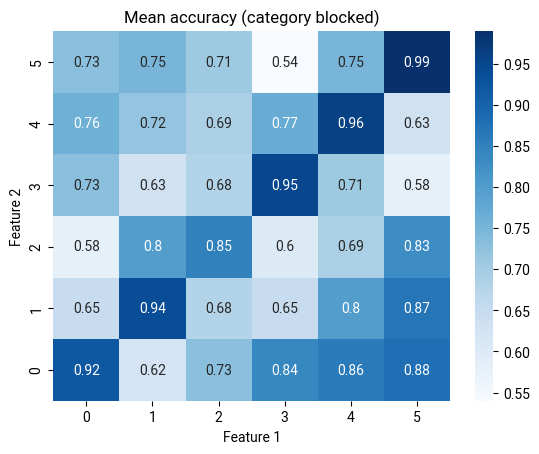

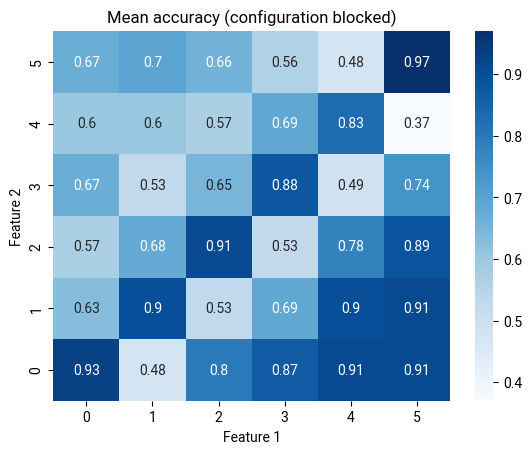

In [114]:
# %% Heatmaps for accurac per configuration
# for all participants
means = list(
    df_configurations[[f'config_{num}' for num in configurations]].mean())
# turn means into a 6x6 matrix and round each value to 2 decimal places
matrix = np.array([round(m, 2) for m in means]).reshape(6, 6)

ax = sb.heatmap(matrix, cmap="Blues", annot=True)
ax.invert_yaxis()
ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_title('Mean accuracy (all groups)')
fname = "Mean_per_Config.png"
plt.savefig(f'{figures_path}/{fname}', bbox_inches='tight', dpi=300)
plt.show()

for group, numbers in conditions.items():
    # filter by groups
    mask = df_configurations['ppt_number'].apply(numbers)
    # apply filter of groups, and average the accuracy for each FV
    means = list([df_configurations.loc[mask, f'config_{num}'].mean()
                  for num in configurations])
    matrix = np.array([round(m, 2) for m in means]).reshape(6, 6)
    ax = sb.heatmap(matrix, cmap="Blues", annot=True)
    ax.invert_yaxis()
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.set_title(f'Mean accuracy ({group})')
    fname = f"Mean_per_Config_{group}.png"
    plt.savefig(f'{figures_path}/{fname}',
                bbox_inches='tight', dpi=300, transparent=True)
    plt.show()

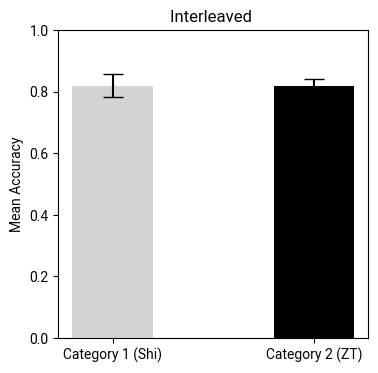

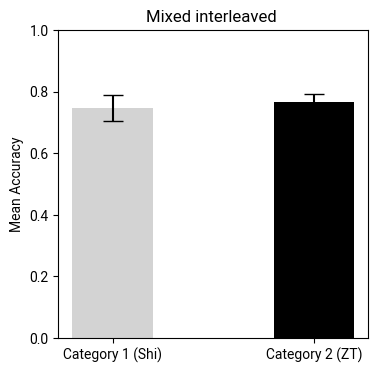

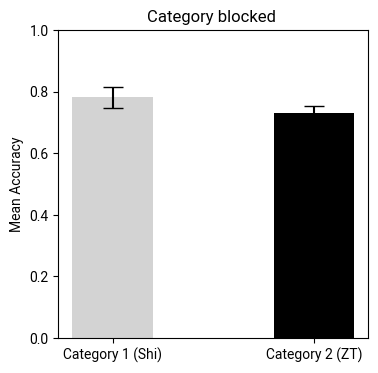

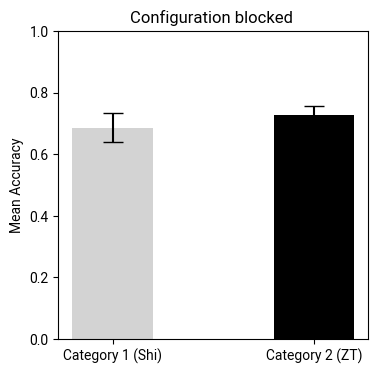

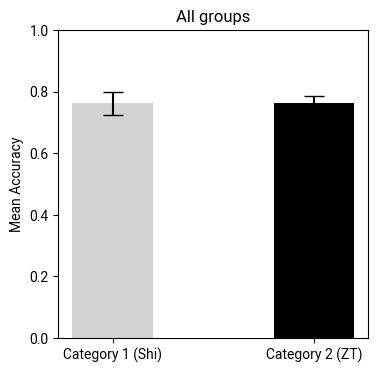

In [115]:
# %% Means per Category (ZT / Shi)
categories = ['Category 1 (Shi)', 'Category 2 (ZT)']
for group, numbers in conditions.items():
    # filter by groups
    mask = df_configurations['ppt_number'].apply(numbers)
    # apply filter of groups, and average the accuracy for each FV
    SHI = [
        np.mean(df_configurations.loc[mask, f'config_{num}']) for num in SHI_configs]
    ZT = [np.mean(df_configurations.loc[mask,
                                        f'config_{num}']) for num in ZT_configs]
    # sanity check
    if len(SHI) != len(SHI_configs) and len(ZT) != len(ZT_configs):
        print('Warning, sanity check needed!')

    x = categories
    y = [SHI, ZT]

    # print(np.mean(y))
    w = 0.4

    fig, ax = plt.subplots(figsize=(4, 4))
    ax.bar(
        x,
        height=[np.mean(yi) for yi in y],
        yerr=[np.std(yi) / np.sqrt(np.size(yi)) for yi in y],
        width=w,
        capsize=7,
        color=['#D3D3D3', '#000000'],
        zorder=-1,
    )
    plt.title(f'{group.capitalize()} ')
    plt.ylabel("Mean Accuracy")
    plt.ylim(0, 1)

    # Add significance stars above the bars, adjust height (y)

    p_value_ZT_SHI = stats.ttest_ind(SHI, ZT, alternative='two-sided')[1]

    add_significance(ax, 0+w/2, 0 + w*2, max(np.mean(SHI),
                     np.mean(ZT)), p_value_ZT_SHI,
                    #  num_bars=len(categories)
                     )

    if save_figs == True:
        plt.savefig(f'{figures_path}/Mean_By_Categories_{group}.png',
                    dpi=1000, transparent=True)
    plt.show()


# %% Create same figure but across participants

SHI_all = [
    np.mean(df_configurations[f'config_{confignum}']) for confignum in SHI_configs]
ZT_all = [
    np.mean(df_configurations[f'config_{cofignum}']) for cofignum in ZT_configs]
# sanity check
if len(SHI_all) != len(SHI_configs) and len(ZT_all) != len(ZT_configs):
    print('Warning, sanity check needed!')

x = categories
y = [SHI_all, ZT_all]

w = 0.4

fig, ax = plt.subplots(figsize=(4, 4))
ax.bar(
    x,
    height=[np.mean(yi) for yi in y],
    yerr=[np.std(yi) / np.sqrt(np.size(yi)) for yi in y],
    width=w,
    capsize=7,
    color=['#D3D3D3', '#000000'],
    zorder=-1,
)
plt.title('All groups')
plt.ylabel("Mean Accuracy")
plt.ylim(0, 1)

# Add significance stars above the bars, adjust height (y)

p_value_ZT_SHI_all = stats.ttest_ind(
    SHI_all, ZT_all, alternative='two-sided')[1]

add_significance(ax, 0+w/2, 0 + w*2, max(np.mean(SHI_all),
                 np.mean(ZT_all)), p_value_ZT_SHI_all,
                #  num_bars=len(categories)
                 )

if save_figs == True:
    plt.savefig(f'{figures_path}/Mean_By_Categories.png',
                dpi=1000, transparent=True)
plt.show()


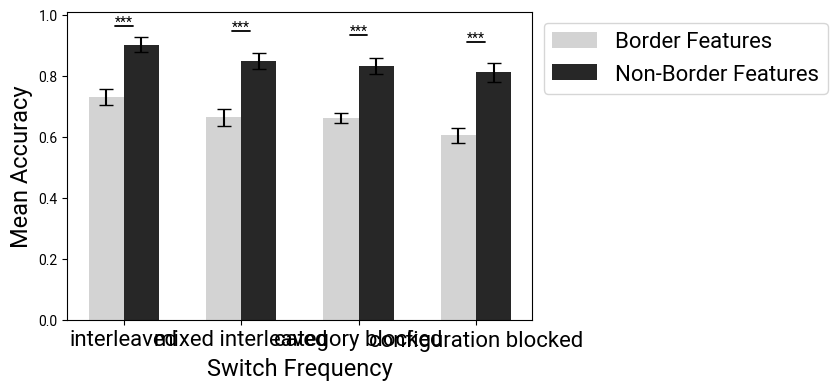

In [116]:
# %% Fig. Border vs. No border per condition (Single Figure with Six Bars)
x_labels = list(conditions.keys())
x_axis = np.arange(len(x_labels))
border_features = [1, 2]

y_data = {group: [] for group in conditions}

for group, numbers in conditions.items():
    # Filter by groups
    mask = df_results['ppt_number'].apply(numbers)

    # Calculate mean accuracy for border and non-border features
    y1 = [df_results.loc[mask, f'Accuracy_FV{border_feature}']
          for border_feature in border_features]
    y1 = sum(y1) / len(y1)
    y2 = [df_results.loc[mask, f'Accuracy_FV{feature}']
          for feature in features if feature not in border_features]
    y2 = sum(y2) / len(y2)

    y_data[group] = [y1.tolist(), y2.tolist()]

width = 0.3  # Adjust width for clearer visualization
colors = ['#D3D3D3', '#272727']  # Colors for border and non-border features

fig, ax = plt.subplots(figsize=(6, 4))

bars = []
for i, group in enumerate(conditions):
    bars.append(ax.bar(
        x_axis[i] - width / 2, np.mean(y_data[group][0]), width=width,
        yerr=np.std(y_data[group][0]) / np.sqrt(np.size(y_data[group][0])),
        capsize=5, color=colors[0], label='Border Features' if i == 0 else "", zorder=-1
    ))
    bars.append(ax.bar(
        x_axis[i] + width / 2, np.mean(y_data[group][1]), width=width,
        yerr=np.std(y_data[group][1]) / np.sqrt(np.size(y_data[group][1])),
        capsize=5, color=colors[1], label='Non-Border Features' if i == 0 else "", zorder=-1
    ))

plt.xticks(x_axis, x_labels, fontsize=16)
plt.xlabel("Switch Frequency", fontsize=17)
plt.ylabel("Mean Accuracy", fontsize=17)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=16)
# plt.tight_layout()

# Add significance bars
for i in range(len(x_axis)):
    p_value = stats.ttest_ind(
        y_data[x_labels[i]][0], y_data[x_labels[i]][1], alternative='two-sided')[1]
    base_height = max(
        np.mean(y_data[x_labels[i]][0]), np.mean(y_data[x_labels[i]][1]))
    add_significance(ax, x1=i - width / 4, x2=i + width / 4,
                     y_base=base_height, p_value=p_value,
                    #  num_bars=len(x_axis)
                     )

# Save the figure
if save_figs:
    plt.savefig(f'{figures_path}/Border_vs_NonBorder.png',
                dpi=1000, bbox_inches="tight", transparent=True)
plt.show()

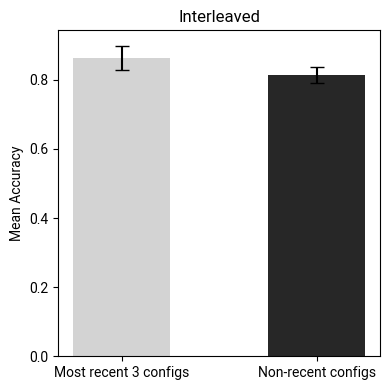

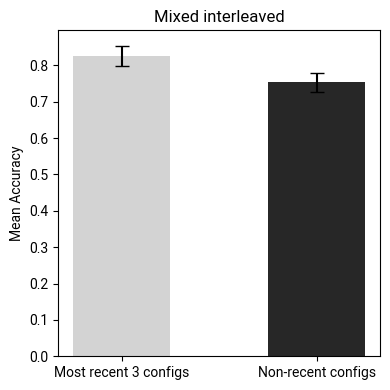

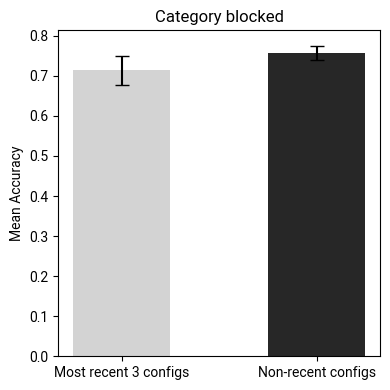

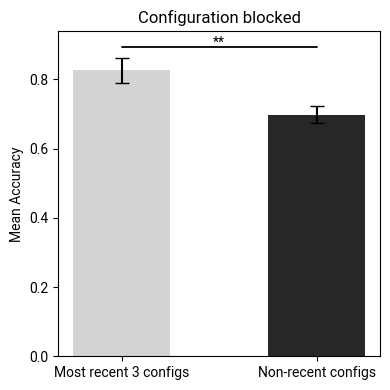

In [117]:

# %% Fig. Recency Effect per condition
x = ['Most recent 3 configs', 'Non-recent configs']

border_features = [1, 2]
for group, numbers in conditions.items():
    # filter by groups
    mask = df_results['ppt_number'].apply(numbers)
    # apply filter of groups, and average the accuracy for each FV
    y = [df_results.loc[mask, 'Recent_3_configs'],
         df_results.loc[mask, 'Nonrecent_configs']]

    w = 0.5  # Adjust width for closer bars
    fig, ax = plt.subplots(figsize=(4, 4))
    # ax.subplots(figsize=(4, 4))
    bars = ax.bar(
        x,
        height=[np.mean(yi) for yi in y],
        yerr=[np.std(yi) / np.sqrt(np.size(yi)) for yi in y],
        width=w,
        capsize=5,
        color=['#D3D3D3', '#272727', ],
        zorder=-1,
    )

    plt.title(f'{group.capitalize()}', fontsize=12)
    # plt.xlabel("Feature Value")
    plt.ylabel("Mean Accuracy")
    # plt.ylim(0, 1.2)
    plt.tight_layout()  # Ensure tight spacingx

    # add significance bars
    for i, j in combinations(range(len(y)), 2):
        # Perform t-test
        p_value_cond = stats.ttest_ind(y[i], y[j], alternative='two-sided')[1]

        # Base height (highest bar of the two)
        base_height = max(np.mean(y[i]), np.mean(y[j]))

        # Add significance bar with dynamic spacing
        add_significance(ax, x1=i, x2=j, y_base=base_height,
                         p_value=p_value_cond,
                        #  num_bars=len(y)
                         )

    # Save with correct filename**
    if save_figs == True:
        plt.savefig(f'{figures_path}/{group}_RecencyEffect.png',
                    dpi=1000, transparent=True)
    plt.show()

/var/folders/fx/g0sdqwp52yxgfbdpddlbxx8c0000gr/T/ipykernel_23305/4042672673.py:80: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig2.show()


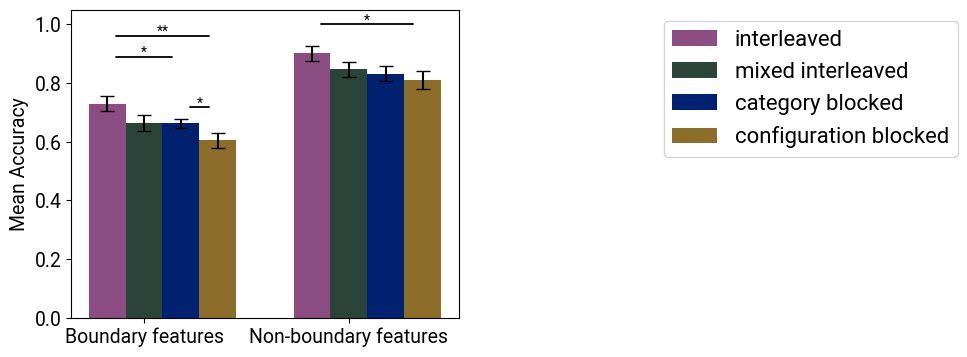

In [132]:

# %% Fig. Border vs. No border per condition on the one figure
conditions = {
    'interleaved': lambda num: num <= 60 and num % 2 != 0,
    'mixed interleaved': lambda num: num <= 60 and num % 2 == 0,
    'category blocked': lambda num: num > 90,
    'configuration blocked': lambda num: 60 < num <= 90,
}
comparisons = list(combinations(conditions, 2))
bar_positions = {
    "interleaved": -0.18,
    "mixed interleaved": 0,
    "category blocked": 0.18,
    "configuration blocked":0.36 ,
    
}

fig2, ax2 = plt.subplots(figsize=(5, 4))
x_axis = np.arange(len([1, 2]))

y_data = {}
for group, numbers in conditions.items():
    # filter by groups
    mask = df_results['ppt_number'].apply(numbers)
    # apply filter of groups, and average the accuracy for each FV
    y1 = [df_results.loc[mask, f'Accuracy_FV{border_feature}']
          for border_feature in border_features]
    y1 = sum(y1)/len(y1)
    y1_list = y1.tolist()

    y2 = [df_results.loc[mask, f'Accuracy_FV{feature}']
          for feature in features if feature not in border_features]
    y2 = sum(y2)/len(y2)
    y2_list = y2.tolist()

    y_data[group] = [y1_list, y2_list]

width = 0.18
colors = ['#8C4E82', '#2a4439', '#002070', '#8C6E2A']
bars = []

for i, group in enumerate(conditions):
    bar = ax2.bar(
        x_axis + (i-1)*width,
        height=[np.mean(yi) for yi in y_data[group]],
        width=width,
        yerr=[np.std(yi)/np.sqrt(np.size(yi)) for yi in y_data[group]],
        capsize=5,
        color=colors[i],
        zorder=-1,
    )
    bars.append(bar)

plt.xticks(x_axis, ['Boundary features', 'Non-boundary features'], fontsize=14)
# plt.xlabel("Condition")
plt.ylabel("Mean Accuracy", fontsize=14)
plt.tick_params(axis='x', labelsize=14)
plt.tick_params(axis='y', labelsize=14)

# plt.title("")
p_values=[]
for i in range(len(x_axis)):
    for g1, g2 in comparisons:
        y1, y2 = y_data[g1][i], y_data[g2][i]
        p_value = stats.ttest_ind(y1, y2, alternative='two-sided')[1]
        p_values.append(p_value)
        x1 = x_axis[i] + bar_positions[g1]
        x2 = x_axis[i] + bar_positions[g2]
        base_height = max(np.mean(y1), np.mean(y2)) - 0.15
        final_height = base_height + \
            (0.105 * abs(bar_positions[g1]-bar_positions[g2])/width)
        add_significance(ax2, x1 + width/4, x2 - width/4,
                         final_height, p_value, 
                        #  num_bars
                         )

lgd = ax2.legend(bars, conditions, bbox_to_anchor=(1.5, 1), fontsize=16)
if save_figs:
    plt.savefig(f'{figures_path}/border_nonborder_all', bbox_extra_artists=(
        lgd,), bbox_inches="tight", dpi=1000, transparent=True)
fig2.show()

In [129]:
p_values

[np.float64(0.10052419292343998),
 np.float64(0.0013861691945329564),
 np.float64(0.13504998962886103),
 np.float64(0.14750620305036394),
 np.float64(0.029743339121416607),
 np.float64(0.38946259737307753)]

/var/folders/fx/g0sdqwp52yxgfbdpddlbxx8c0000gr/T/ipykernel_23305/834477455.py:77: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig2.show()


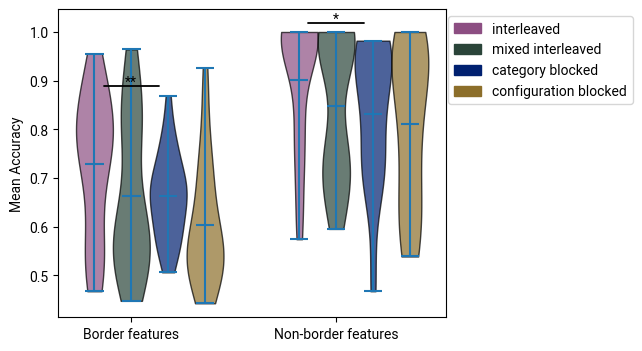

In [119]:

# %% Violin plot of previous bar plot: birder features vs non border features
fig2, ax2 = plt.subplots(figsize=(5, 4))
x_axis = np.arange(len([1, 2]))

y_data = {}
for group, numbers in conditions.items():
    mask = df_results['ppt_number'].apply(numbers)
    y1 = [df_results.loc[mask, f'Accuracy_FV{border_feature}']
          for border_feature in border_features]
    y1 = sum(y1)/len(y1)
    y1_list = y1.tolist()

    y2 = [df_results.loc[mask, f'Accuracy_FV{feature}']
          for feature in features if feature not in border_features]
    y2 = sum(y2)/len(y2)
    y2_list = y2.tolist()

    y_data[group] = [y1_list, y2_list]

width = 0.18
colors = ['#8C4E82', '#2a4439', '#002070', '#8C6E2A']
violin_plots = []

# Create positions and data for violin plots
positions = []
all_data = []
for i, group in enumerate(conditions.keys()):  # Fix: iterate through group names
    positions.extend([
        x_axis[0] + (i-1)*width,  # Border features
        x_axis[1] + (i-1)*width   # Non-border features
    ])
    # Now correctly accesses y_data using group names
    all_data.extend(y_data[group])

# Create violin plots
violins = ax2.violinplot(
    all_data,
    positions=positions,
    widths=width,
    showmeans=True,
    showmedians=False
)

# Color the violins
for body, color in zip(violins['bodies'], np.repeat(colors, 2)):
    body.set_facecolor(color)
    body.set_edgecolor('black')
    body.set_alpha(0.7)

# Maintain existing formatting and statistical annotations
plt.xticks(x_axis, ['Border features', 'Non-border features'])
plt.ylabel("Mean Accuracy")

# Create proxy artists for legend (to match original bar legend)
bars = [mpatches.Patch(color=color, label=group)
        for group, color in zip(conditions, colors)]

# Keep existing significance and saving code
for i in range(len(x_axis)):
    for g1, g2 in comparisons:
        y1, y2 = y_data[g1][i], y_data[g2][i]
        p_value = stats.ttest_ind(y1, y2, alternative='two-sided')[1]
        x1 = x_axis[i] + bar_positions[g1]
        x2 = x_axis[i] + bar_positions[g2]
        base_height = max(np.mean(y1), np.mean(y2)) - 0.15
        final_height = base_height + \
            (0.105 * abs(bar_positions[g1]-bar_positions[g2])/width)
        add_significance(ax2, x1 + width/4, x2 - width/4,
                         final_height, p_value, 
                        #  num_bars
                         )

lgd = ax2.legend(bars, conditions, bbox_to_anchor=(1.5, 1))
if save_figs:
    plt.savefig("violin_border_nonborder", bbox_extra_artists=(lgd,),
                bbox_inches="tight", dpi=1000, transparent=True)
fig2.show()

/var/folders/fx/g0sdqwp52yxgfbdpddlbxx8c0000gr/T/ipykernel_23305/1424070635.py:57: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig2.show()


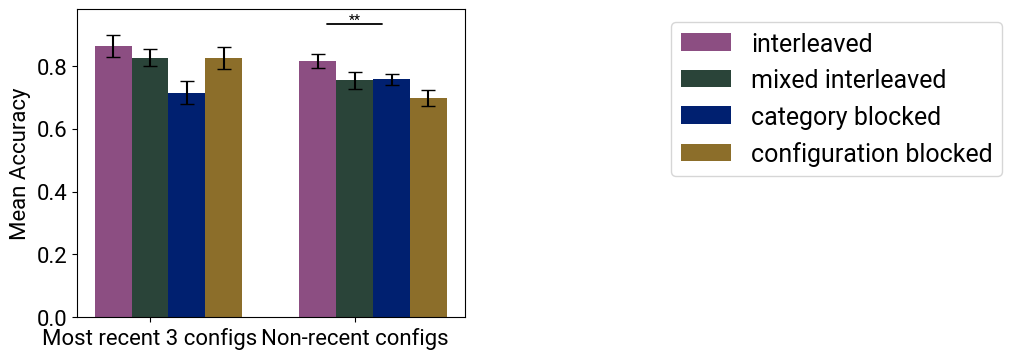

In [120]:

# %% Fig. Recency Effect per condition on the one figure
fig2, ax2 = plt.subplots(figsize=(5, 4))
x_axis = np.arange(len([1, 2]))

y_data = {}
border_features = [1, 2]
for group, numbers in conditions.items():
    # filter by groups
    mask = df_results['ppt_number'].apply(numbers)
    # apply filter of groups, and average the accuracy for each FV
    y = [df_results.loc[mask, 'Recent_3_configs'].tolist(),
         df_results.loc[mask, 'Nonrecent_configs'].tolist()]
    y_data[group] = y


width = 0.18
colors = ['#8C4E82', '#2a4439', '#002070', '#8C6E2A']
bars = []

for i, group in enumerate(conditions):
    bar = ax2.bar(
        x_axis + (i-1)*width,
        height=[np.mean(yi) for yi in y_data[group]],
        width=width,
        yerr=[np.std(yi)/np.sqrt(np.size(yi)) for yi in y_data[group]],
        capsize=5,
        color=colors[i],
        zorder=-1,
    )
    bars.append(bar)

plt.xticks(x_axis, ['Most recent 3 configs', 'Non-recent configs'])
# plt.xlabel("Condition")
plt.ylabel("Mean Accuracy", fontsize=16)
# plt.title("")
plt.tick_params(axis='x', labelsize=16)
plt.tick_params(axis='y', labelsize=16)

for i in range(len(x_axis)):
    for g1, g2 in comparisons:
        y1, y2 = y_data[g1][i], y_data[g2][i]
        p_value = stats.ttest_ind(y1, y2, alternative='two-sided')[1]
        x1 = x_axis[i] + bar_positions[g1]
        x2 = x_axis[i] + bar_positions[g2]
        base_height = max(np.mean(y1), np.mean(y2)) - 0.15
        final_height = base_height + \
            (0.105 * abs(bar_positions[g1]-bar_positions[g2])/width)
        add_significance(ax2, x1 + width/4, x2 - width/4,
                         final_height, p_value, 
                        #  num_bars
                         )

lgd = ax2.legend(bars, conditions, bbox_to_anchor=(1.5, 1), fontsize=18)
if save_figs:
    plt.savefig(f'{figures_path}/Recency_Effect_all', bbox_extra_artists=(
        lgd,), bbox_inches="tight", dpi=1000, transparent=True)
fig2.show()

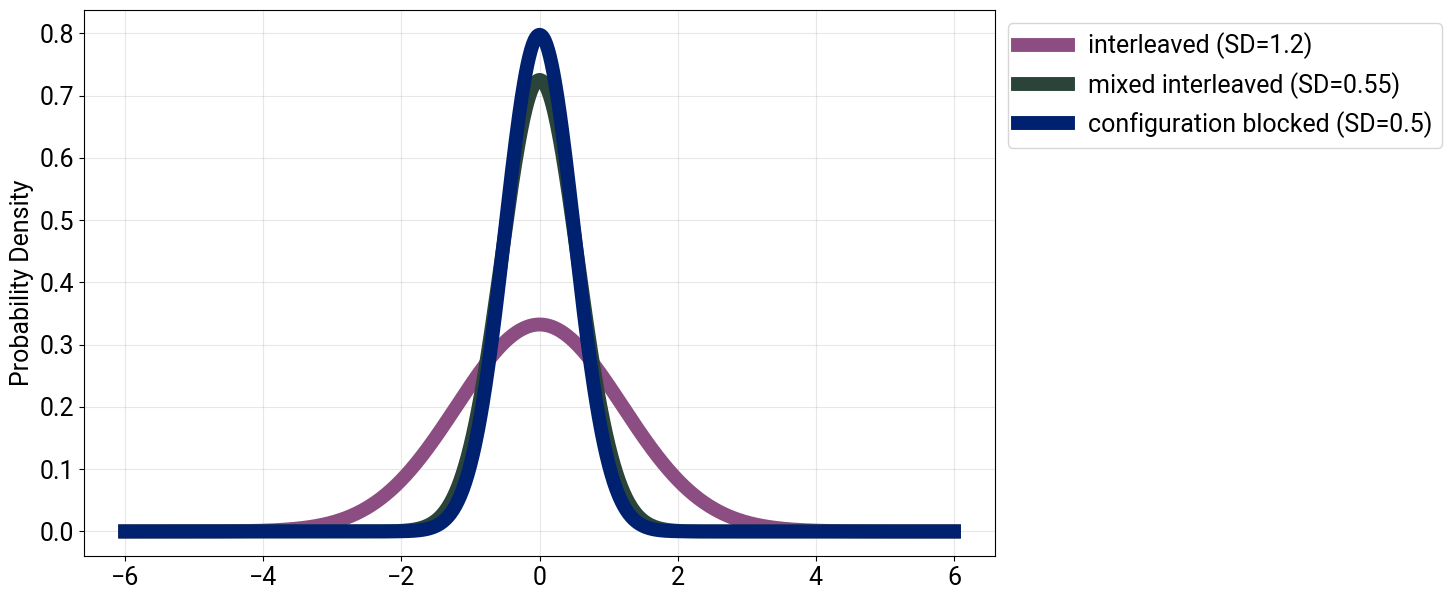

In [121]:
# %% Gaussian graphs for each cond

# dictionary with params and accuracy
# these are the params for TRAINING
parameter_accuracy_model = {
    'interleaved': {'par': 1.2, 'acc': 0.749266666666667},
    'mixed interleaved': {'par': 0.55, 'acc': 0.703733333333335},
    'configuration blocked': {'par': 0.5, 'acc': 0.7024761904761995},
    # 'category blocked': {'par': 1.8, 'acc': 0.6435}
}
colors = ['#8C4E82', '#2a4439', '#002070',
          '#8C6E2A']  # Matches previous colors

# the maximum SD to set the x-axis range
max_sd = max(values['par'] for values in parameter_accuracy_model.values())
x = np.linspace(-5 * max_sd, 5 * max_sd, 1000)

plt.figure(figsize=(10, 6))

# PDF
for (condition, values), color in zip(parameter_accuracy_model.items(), colors):
    sd = values['par']
    y = (1 / (sd * np.sqrt(2 * np.pi))) * np.exp(-x**2 / (2 * sd**2))
    plt.plot(x, y, color=color, label=f'{condition} (SD={sd})', linewidth=10.0)

# Customize plot
# plt.title('Gaussian Distributions by Condition', fontsize=18)
# plt.xlabel('Value')
plt.ylabel('Probability Density', fontsize=18)
plt.legend(fontsize=16)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.tick_params(axis='x', labelsize=18)
plt.tick_params(axis='y', labelsize=18)

lgd = plt.legend(bbox_to_anchor=(1, 1), loc='upper left', fontsize=18)
if save_figs:
    plt.savefig(f'{figures_path}/Params_Model', bbox_extra_artists=(
        lgd,), bbox_inches="tight", dpi=1000, transparent=True)
plt.show()

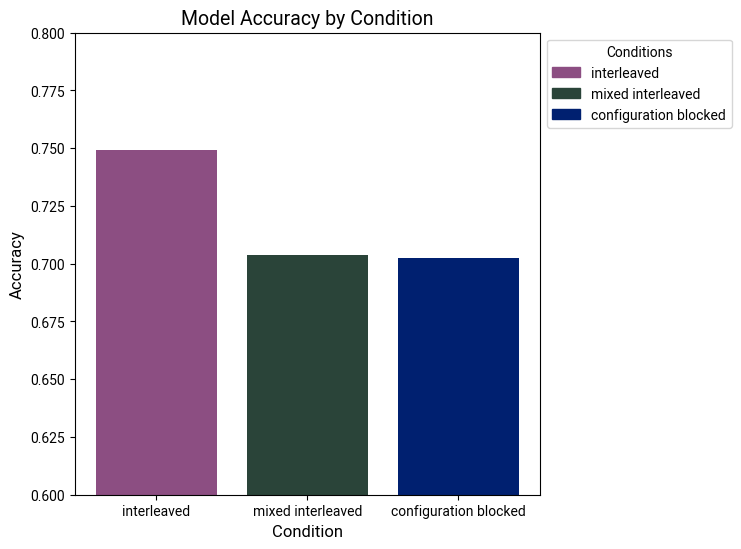

In [122]:
# %% Model Accuracy

colors = ['#8C4E82', '#2a4439', '#002070', '#8C6E2A']

# Extract keys and accuracies in order
conditions = list(parameter_accuracy_model.keys())
accuracies = [parameter_accuracy_model[cond]['acc'] for cond in conditions]

# Create plot
plt.figure(figsize=(6, 6))
bars = plt.bar(conditions, accuracies, color=colors)

# Customize plot
plt.title('Model Accuracy by Condition', fontsize=14)
plt.xlabel('Condition', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.ylim(0.6, 0.8)  # Adjusted to emphasize differences
# plt.grid(axis='y', alpha=0.3)

# Create legend outside plot
patches = [mpatches.Patch(color=colors[i], label=cond)
           for i, cond in enumerate(conditions)]
lgd = plt.legend(handles=patches, title='Conditions',
                 bbox_to_anchor=(1, 1), loc='upper left')

# Save figure (assuming these variables are defined elsewhere)
save_figs = True  # Set to False to disable saving
figures_path = './figures'  # Set your path here

if save_figs:
    plt.savefig(f'{figures_path}/Model_accuracy_all',
                bbox_extra_artists=(lgd,),
                bbox_inches="tight",
                dpi=1000,
                transparent=True)

plt.show()

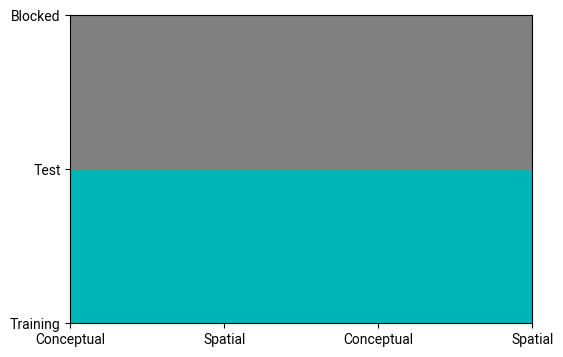

In [123]:
# %%
df_results['n_trials_lost_training'] = 180 - df_results['trialN_training']
df_results['n_trials_lost_test'] = 252 - df_results['trialN_test']
# %%
# print(f"Min trialN training: {min(df_results['trialN_training'])},\n "
#       f"Max trialN training: {max(df_results['trialN_training'])},\n "
#       f"Min trialN test: {min(df_results['trialN_test'])},\n"
#       f"Max trialN test: {max(df_results['trialN_test'])}")

# %%

# Data for visualization (rows and columns for tasks)
data = {
    'Interleaved': ['#00B5B8'] * 144,
    'Blocked': ['#808080'] * 144
}

# Set up the figure and axes
fig, ax = plt.subplots(figsize=(10, 4))
ax.set_xticks(np.arange(4))  # Example with 4 columns for tasks
ax.set_yticks(np.arange(3))  # Example with 3 rows for conditions

# Create boxes (rectangles)
for i, (condition, color_list) in enumerate(data.items()):
    for j in range(4):
        # Add each colored box
        ax.add_patch(plt.Rectangle((j, i), 1, 1, color=color_list[j]))

# Labels
ax.set_xticklabels(['Conceptual', 'Spatial', 'Conceptual', 'Spatial'])
ax.set_yticklabels(['Training', 'Test', 'Blocked'])

ax.set_aspect('equal')
plt.show()
